# The University of Azad Jammu and Kashmir
**Department of Software Engineering — Digital Image Processing Lab**

Lab Instructor: Engr. Fahad Nisar &nbsp;|&nbsp; Semester: Fifth &nbsp;|&nbsp; Session: 2024-28 (SE)

## Lab Task # 03 — Image Enhancement and Intensity Transformations
Assigned On: November 02, 2026 &nbsp;|&nbsp; Due Date: November 09, 2026, 11:59 PM

| | |
|---|---|
| **Student Name** | Sheikh Haseeb-ur-Rehman |
| **Roll No. (complete)** | 2024-SE-31 |

**Objective:** Calculate, implement, and compare grayscale intensity transformations, histogram enhancement, and thresholding while preventing overflow and interpreting their effects.

**Notebook map:** Setup → Image loading & numeric safety → Operations 1–11. Every operation has (a) a **dry run** with a typed hand calculation that is verified in Python, and (b) the **image task** on my personally selected image, followed by brief observations.

**Submitted files:** `2024-SE-31-LAB03.ipynb` (this notebook), `2024-SE-31-LAB03.docx` (report) and `input_image.jpg` (input image, same folder as the notebook).

## 0. Setup and helper functions
All images are displayed with `cmap="gray", vmin=0, vmax=255` so Matplotlib never silently rescales the intensities.

In [1]:
%pip install opencv-python
import cv2
import numpy as np
import matplotlib.pyplot as plt

STUDENT_NAME = "Sheikh Haseeb-ur-Rehman"
ROLL_NO      = "2024-SE-31"
print(f"Student: {STUDENT_NAME}   |   Roll No.: {ROLL_NO}")
print(f"OpenCV {cv2.__version__}   |   NumPy {np.__version__}")

plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10, "axes.titleweight": "bold"})


def show_images(images, titles, suptitle=None, ncols=None):
    """Show grayscale images side by side with the fixed display range 0-255."""
    n = len(images)
    ncols = ncols or n
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(min(4.6 * ncols, 15), 4.6 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()


def print_table(headers, rows, title=None):
    """Print a plain-text table (used for every dry-run calculation)."""
    rows = [[str(c) for c in r] for r in rows]
    widths = [max(len(str(h)), *(len(r[i]) for r in rows)) for i, h in enumerate(headers)]
    if title:
        print(title)
    print(" | ".join(str(h).ljust(w) for h, w in zip(headers, widths)))
    print("-+-".join("-" * w for w in widths))
    for r in rows:
        print(" | ".join(c.ljust(w) for c, w in zip(r, widths)))
    print()


def verify(label, hand, computed):
    """Compare a hand-calculated result with the Python result."""
    ok = np.allclose(np.asarray(hand, dtype=float), np.asarray(computed, dtype=float))
    print(("✔ MATCH    " if ok else "✘ MISMATCH ") + label)
    assert ok, "Hand calculation does not match Python: " + label


def round_half_up(x):
    """Round to the nearest integer, with .5 rounded UPWARD (as required in dry run 7)."""
    return np.floor(np.asarray(x, dtype=np.float64) + 0.5)


def img_stats(name, a):
    a = np.asarray(a)
    return (name, f"{a.mean():.2f}", f"{a.std():.2f}", int(a.min()), int(a.max()),
            f"{100 * np.mean(a == 0):.2f}", f"{100 * np.mean(a == 255):.2f}")


def print_stats(items, title=None):
    print_table(["Image", "Mean", "Std-dev", "Min", "Max", "% pixels = 0", "% pixels = 255"],
                [img_stats(n, a) for n, a in items], title)


def hist_counts(a):
    """256-bin histogram of an 8-bit image (index = intensity)."""
    return np.bincount(np.asarray(a).ravel(), minlength=256)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\HP\anaconda3\python.exe -m pip install --upgrade pip


Student: Sheikh Haseeb-ur-Rehman   |   Roll No.: 2024-SE-31
OpenCV 5.0.0   |   NumPy 2.5.4


## Part A — Image loading and numeric safety

### Why wider arithmetic types and clipping?
A `uint8` pixel can only store 0–255. If arithmetic is done *inside* `uint8`, results outside that range **wrap around** (overflow) instead of saturating. The safe recipe used throughout this lab is:

1. convert to a wider type (`int16` for integer maths, `float64` for fractional maths);
2. compute the transformation;
3. `np.clip(..., 0, 255)`;
4. convert back with `.astype(np.uint8)` — which **truncates** any fractional part (no rounding unless the exercise asks for it).

In [2]:
# Demonstration of overflow: the SAME addition done unsafely and safely
demo = np.array([30, 80, 128, 180, 240], dtype=np.uint8)

unsafe = demo + np.uint8(50)                                  # arithmetic stays in uint8 -> wraps around
safe   = np.clip(demo.astype(np.int16) + 50, 0, 255).astype(np.uint8)

print("Original pixels      :", demo)
print("UNSAFE  uint8 + 50   :", unsafe, "  <- 180+50=230 is fine, but 240+50=290 wraps to 34 (dark!)")
print("SAFE    int16 + clip :", safe,   "  <- 290 is clipped to 255 (white stays white)")

Original pixels      : [ 30  80 128 180 240]
UNSAFE  uint8 + 50   : [ 80 130 178 230  34]   <- 180+50=230 is fine, but 240+50=290 wraps to 34 (dark!)
SAFE    int16 + clip : [ 80 130 178 230 255]   <- 290 is clipped to 255 (white stays white)


### Load and validate the 8-bit grayscale image
The input is my personally selected image, generated with Google Gemini (`input_image.jpg`, 2048 × 2048 pixels, well above the 300 × 300 minimum). It is read with `cv2.IMREAD_GRAYSCALE`, validated, and then locked as **read-only** so the original can never be changed by accident; every operation below creates a *new* array.

Shape (rows, cols): (2048, 2048)
dtype             : uint8
Minimum intensity : 0
Maximum intensity : 255
Writable?         : False (False = original is protected)


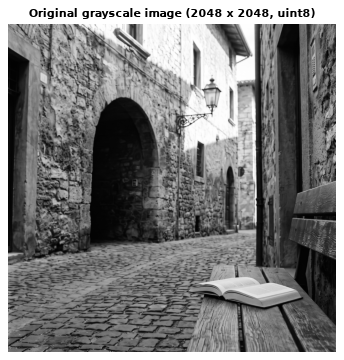

In [3]:
IMAGE_PATH = "input_image.jpg"

original = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)

# ---- validation ----
if original is None:
    raise FileNotFoundError(f"{IMAGE_PATH} not found - keep it in the same folder as this notebook")
assert original.ndim == 2,            "image is not single-channel (grayscale)"
assert original.dtype == np.uint8,    "image is not 8-bit"
assert min(original.shape) >= 300,    "image is smaller than 300 x 300"

original.setflags(write=False)          # keep the original unchanged (read-only)
height, width = original.shape

print("Shape (rows, cols):", original.shape)
print("dtype             :", original.dtype)
print("Minimum intensity :", original.min())
print("Maximum intensity :", original.max())
print("Writable?         :", original.flags.writeable, "(False = original is protected)")

show_images([original], [f"Original grayscale image ({width} x {height}, uint8)"])

---
## 1. Brightness adjustment
Rule: &nbsp; **s = r + β**, then clip to 0–255. &nbsp; β = +40 (brighter) and β = −40 (darker).

### Dry run 1 — pixels [30, 80, 128, 180, 240]
| r | r + 40 (raw) | clipped to 0–255 | final uint8 | r − 40 (raw) | clipped to 0–255 | final uint8 |
|---|---|---|---|---|---|---|
| 30  | 70  | 70  | **70**  | −10 | 0   | **0**   |
| 80  | 120 | 120 | **120** | 40  | 40  | **40**  |
| 128 | 168 | 168 | **168** | 88  | 88  | **88**  |
| 180 | 220 | 220 | **220** | 140 | 140 | **140** |
| 240 | 280 | 255 | **255** | 200 | 200 | **200** |

Only 240 (raw 280) is clipped for +40, and only 30 (raw −10) is clipped for −40.

In [4]:
P = np.array([30, 80, 128, 180, 240], dtype=np.uint8)

# ---- hand-calculated values (typed from the table above) ----
hand_plus_raw,  hand_plus_final  = [70, 120, 168, 220, 280], [70, 120, 168, 220, 255]
hand_minus_raw, hand_minus_final = [-10, 40, 88, 140, 200],  [0, 40, 88, 140, 200]

# ---- Python verification (int16 is wide enough: -40 ... 295) ----
plus_raw,  minus_raw  = P.astype(np.int16) + 40, P.astype(np.int16) - 40
plus_final  = np.clip(plus_raw,  0, 255).astype(np.uint8)
minus_final = np.clip(minus_raw, 0, 255).astype(np.uint8)

print_table(["r", "r+40 raw", "clipped", "uint8", "r-40 raw", "clipped", "uint8"],
            [[p, a, np.clip(a, 0, 255), f, b, np.clip(b, 0, 255), g]
             for p, a, f, b, g in zip(P, plus_raw, plus_final, minus_raw, minus_final)],
            "Dry run 1 - brightness (computed in Python)")

verify("raw values for +40",   hand_plus_raw,    plus_raw)
verify("final values for +40", hand_plus_final,  plus_final)
verify("raw values for -40",   hand_minus_raw,   minus_raw)
verify("final values for -40", hand_minus_final, minus_final)

Dry run 1 - brightness (computed in Python)
r   | r+40 raw | clipped | uint8 | r-40 raw | clipped | uint8
----+----------+---------+-------+----------+---------+------
30  | 70       | 70      | 70    | -10      | 0       | 0    
80  | 120      | 120     | 120   | 40       | 40      | 40   
128 | 168      | 168     | 168   | 88       | 88      | 88   
180 | 220      | 220     | 220   | 140      | 140     | 140  
240 | 280      | 255     | 255   | 200      | 200     | 200  

✔ MATCH    raw values for +40
✔ MATCH    final values for +40
✔ MATCH    raw values for -40
✔ MATCH    final values for -40


**Verification:** every hand-calculated raw and final value matches the Python result.

**Lost detail:** with +40 the pixel 240 has raw value 280, so it is clipped to 255; every original value ≥ 215 now maps to the same white (e.g. 240 and 255 become indistinguishable). With −40 the pixel 30 has raw value −10 and becomes 0; every original value ≤ 40 now maps to the same black. Clipping is **irreversible**: the lost differences cannot be recovered by adding or subtracting 40 again. The first cell of Part A also shows what would happen *without* a wide type: 240 + 50 wraps around to 34 (overflow) instead of saturating at 255.

### Image task 1 — brightness β = +40 and β = −40 (NumPy) and +40 with nested loops

Nested-loop +40 result identical to NumPy +40 result: True
Pixels clipped to 255 by +40: 334039 (7.96%)
Pixels clipped to 0   by -40: 800588 (19.09%)


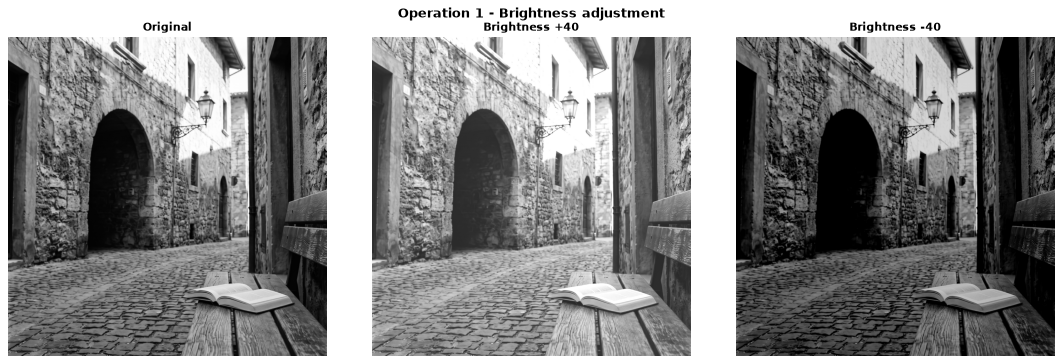

Image          | Mean   | Std-dev | Min | Max | % pixels = 0 | % pixels = 255
---------------+--------+---------+-----+-----+--------------+---------------
Original       | 107.27 | 66.41   | 0   | 255 | 0.01         | 0.39          
Brightness +40 | 145.01 | 62.02   | 40  | 255 | 0.00         | 8.04          
Brightness -40 | 71.57  | 60.76   | 0   | 215 | 19.50        | 0.00          



In [5]:
beta = 40

# ---- NumPy (vectorised, safe) ----
bright = np.clip(original.astype(np.int16) + beta, 0, 255).astype(np.uint8)
darker = np.clip(original.astype(np.int16) - beta, 0, 255).astype(np.uint8)

# ---- Nested loops: brightness +40 ----
bright_loop = np.zeros_like(original)
for row in range(height):
    for col in range(width):
        pixel = int(original[row, col])                    # int() avoids uint8 arithmetic
        bright_loop[row, col] = min(255, max(0, pixel + beta))

print("Nested-loop +40 result identical to NumPy +40 result:", np.array_equal(bright, bright_loop))
assert np.array_equal(bright, bright_loop)

clip_hi = np.sum(original.astype(np.int16) + beta > 255)   # pixels that needed clipping at the top
clip_lo = np.sum(original.astype(np.int16) - beta < 0)     # pixels that needed clipping at the bottom
print(f"Pixels clipped to 255 by +40: {clip_hi} ({100 * clip_hi / original.size:.2f}%)")
print(f"Pixels clipped to 0   by -40: {clip_lo} ({100 * clip_lo / original.size:.2f}%)")

show_images([original, bright, darker],
            ["Original", "Brightness +40", "Brightness -40"],
            "Operation 1 - Brightness adjustment")
print_stats([("Original", original), ("Brightness +40", bright), ("Brightness -40", darker)])

**Observations — brightness**
- β = +40 raises the mean intensity from 107.27 to 145.01; the dark archway becomes visibly lighter, but 7.96 % of the pixels (original r > 215) hit the ceiling and become pure white, so highlight detail on the sunlit wall and sky is lost.
- β = −40 lowers the mean to 71.57; 19.09 % of the pixels (original r < 40) are clipped to 0, so shadow detail in the archway and under the bench merges into flat black. The maximum falls to 215.
- Brightness only **shifts** all values equally; the spread (std-dev 66.41 → 62.02 / 60.76) is not increased — it even drops slightly because of clipping.
- The nested-loop implementation produced an array **identical** to the NumPy result (`True`), but the vectorised version is far faster.

---
## 2. Linear contrast from zero
Rule: &nbsp; **s = α·r + β** with **α = 1.5, β = 0**, then clip to 0–255 and truncate.

### Dry run 2 — pixels [30, 80, 128, 180, 240]
| r | 1.5 × r (raw) | clipped to 0–255 | truncated uint8 | saturated? |
|---|---|---|---|---|
| 30  | 45  | 45  | **45**  | no |
| 80  | 120 | 120 | **120** | no |
| 128 | 192 | 192 | **192** | no |
| 180 | 270 | 255 | **255** | **yes** |
| 240 | 360 | 255 | **255** | **yes** |

Pixels 180 and 240 are saturated (their raw value exceeded 255), so they become the same white value.

In [6]:
hand_raw   = [45, 120, 192, 270, 360]
hand_final = [45, 120, 192, 255, 255]
hand_sat   = [False, False, False, True, True]

raw2   = 1.5 * P.astype(np.float64) + 0          # float64 supports the fractional multiplier
final2 = np.clip(raw2, 0, 255).astype(np.uint8)  # clip first, then truncate to uint8
sat2   = raw2 > 255

print_table(["r", "1.5*r raw", "clipped", "uint8 (truncated)", "saturated?"],
            [[p, a, np.clip(a, 0, 255), f, s] for p, a, f, s in zip(P, raw2, final2, sat2)],
            "Dry run 2 - linear contrast from zero (computed in Python)")

verify("raw values 1.5*r",        hand_raw,   raw2)
verify("final uint8 values",      hand_final, final2)
verify("saturated pixel flags",   hand_sat,   sat2)
print("Saturated input pixels:", P[sat2])

Dry run 2 - linear contrast from zero (computed in Python)
r   | 1.5*r raw | clipped | uint8 (truncated) | saturated?
----+-----------+---------+-------------------+-----------
30  | 45.0      | 45.0    | 45                | False     
80  | 120.0     | 120.0   | 120               | False     
128 | 192.0     | 192.0   | 192               | False     
180 | 270.0     | 255.0   | 255               | True      
240 | 360.0     | 255.0   | 255               | True      

✔ MATCH    raw values 1.5*r
✔ MATCH    final uint8 values
✔ MATCH    saturated pixel flags
Saturated input pixels: [180 240]


**Verification:** all raw, clipped and saturation results match Python. **Saturated pixels: 180 (raw 270) and 240 (raw 360)** — both become 255, so the 60-level difference between them is lost. Unlike brightness, multiplying by 1.5 spreads the values apart (45 → 120 → 192), but it also moves the mid-gray 128 up to 192, which makes the whole result brighter.

### Image task 2 — apply s = 1.5·r + 0 and compare brightness and highlight clipping

Mean brightness: original = 107.27  ->  linear contrast = 149.87
Pixels saturated by 1.5*r (raw > 255): 667354 (15.91% of the image)
Pixels equal to 255 -> original: 0.39%   after: 16.25%


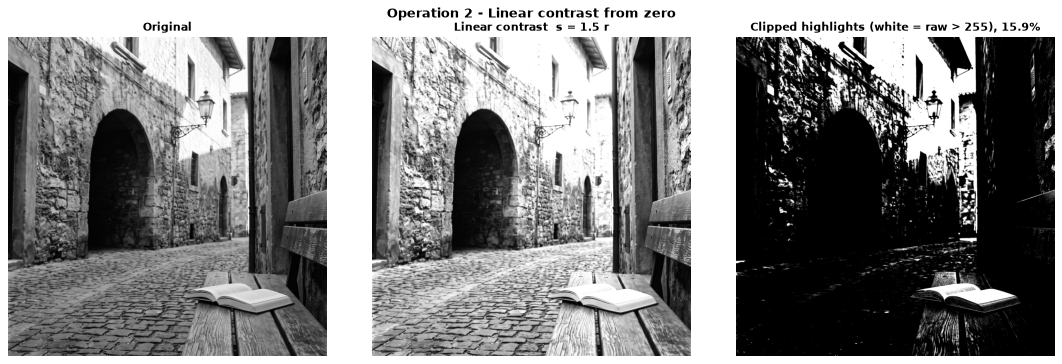

Image       | Mean   | Std-dev | Min | Max | % pixels = 0 | % pixels = 255
------------+--------+---------+-----+-----+--------------+---------------
Original    | 107.27 | 66.41   | 0   | 255 | 0.01         | 0.39          
Linear 1.5r | 149.87 | 81.95   | 0   | 255 | 0.01         | 16.25         



In [7]:
alpha, beta0 = 1.5, 0
raw_lin = alpha * original.astype(np.float64) + beta0
linear  = np.clip(raw_lin, 0, 255).astype(np.uint8)
saturated_mask = raw_lin > 255                       # highlights that were clipped (raw value above 255)

print(f"Mean brightness: original = {original.mean():.2f}  ->  linear contrast = {linear.mean():.2f}")
print(f"Pixels saturated by 1.5*r (raw > 255): {saturated_mask.sum()} ({100 * saturated_mask.mean():.2f}% of the image)")
print(f"Pixels equal to 255 -> original: {100 * np.mean(original == 255):.2f}%   after: {100 * np.mean(linear == 255):.2f}%")

show_images([original, linear, (saturated_mask * 255).astype(np.uint8)],
            ["Original", "Linear contrast  s = 1.5 r", f"Clipped highlights (white = raw > 255), {100 * saturated_mask.mean():.1f}%"],
            "Operation 2 - Linear contrast from zero")
print_stats([("Original", original), ("Linear 1.5r", linear)])

**Observations — linear contrast from zero (α = 1.5, β = 0)**
- The mean brightness rises from 107.27 to 149.87, so the picture is both higher in contrast **and** brighter (std-dev 66.41 → 81.95).
- 15.91 % of the pixels have a raw value above 255 and are clipped; pure-white pixels increase from 0.39 % to 16.25 %. The clipped-highlight mask shows that the sunlit wall, the sky and the open book's pages lose their texture.
- Shadows are not crushed (0 stays 0 and r < 40 stays below 60), but they are lifted slightly because the whole range is multiplied, which adds to the overall brightening.

---
## 3. Contrast centered at 128
Rule: &nbsp; **s = (r − 128)·α + 128** for **α = 1.5** and **α = 0.5**. The pivot 128 stays fixed; values below move toward black (or toward 128 when α < 1), values above move toward white (or toward 128).

### Dry run 3 — pixels [30, 80, 128, 180, 240]
**α = 1.5**

| r | r − 128 | × 1.5 | + 128 (raw) | final (clip, uint8) |
|---|---|---|---|---|
| 30  | −98 | −147 | −19 | **0** |
| 80  | −48 | −72  | 56  | **56** |
| 128 | 0   | 0    | 128 | **128** |
| 180 | 52  | 78   | 206 | **206** |
| 240 | 112 | 168  | 296 | **255** |

**α = 0.5**

| r | r − 128 | × 0.5 | + 128 (raw) | final (clip, uint8) |
|---|---|---|---|---|
| 30  | −98 | −49 | 79  | **79** |
| 80  | −48 | −24 | 104 | **104** |
| 128 | 0   | 0   | 128 | **128** |
| 180 | 52  | 26  | 154 | **154** |
| 240 | 112 | 56  | 184 | **184** |

In [8]:
hand = {
    1.5: dict(shifted=[-98, -48, 0, 52, 112], scaled=[-147, -72, 0, 78, 168],
              raw=[-19, 56, 128, 206, 296],   final=[0, 56, 128, 206, 255]),
    0.5: dict(shifted=[-98, -48, 0, 52, 112], scaled=[-49, -24, 0, 26, 56],
              raw=[79, 104, 128, 154, 184],   final=[79, 104, 128, 154, 184]),
}

for a in (1.5, 0.5):
    shifted = P.astype(np.float64) - 128
    scaled  = shifted * a
    raw3    = scaled + 128
    final3  = np.clip(raw3, 0, 255).astype(np.uint8)
    print_table(["r", "r-128", f"x {a}", "+128 raw", "final uint8"],
                [list(t) for t in zip(P, shifted, scaled, raw3, final3)],
                f"Dry run 3 - centered contrast, alpha = {a}")
    verify(f"alpha={a}: r-128",       hand[a]["shifted"], shifted)
    verify(f"alpha={a}: scaled",      hand[a]["scaled"],  scaled)
    verify(f"alpha={a}: raw",         hand[a]["raw"],     raw3)
    verify(f"alpha={a}: final uint8", hand[a]["final"],   final3)
    print()

print("Linear contrast from zero (dry run 2) gave:", final2, "- note how 128 moved to 192 there.")

Dry run 3 - centered contrast, alpha = 1.5
r   | r-128 | x 1.5  | +128 raw | final uint8
----+-------+--------+----------+------------
30  | -98.0 | -147.0 | -19.0    | 0          
80  | -48.0 | -72.0  | 56.0     | 56         
128 | 0.0   | 0.0    | 128.0    | 128        
180 | 52.0  | 78.0   | 206.0    | 206        
240 | 112.0 | 168.0  | 296.0    | 255        

✔ MATCH    alpha=1.5: r-128
✔ MATCH    alpha=1.5: scaled
✔ MATCH    alpha=1.5: raw
✔ MATCH    alpha=1.5: final uint8

Dry run 3 - centered contrast, alpha = 0.5
r   | r-128 | x 0.5 | +128 raw | final uint8
----+-------+-------+----------+------------
30  | -98.0 | -49.0 | 79.0     | 79         
80  | -48.0 | -24.0 | 104.0    | 104        
128 | 0.0   | 0.0   | 128.0    | 128        
180 | 52.0  | 26.0  | 154.0    | 154        
240 | 112.0 | 56.0  | 184.0    | 184        

✔ MATCH    alpha=0.5: r-128
✔ MATCH    alpha=0.5: scaled
✔ MATCH    alpha=0.5: raw
✔ MATCH    alpha=0.5: final uint8

Linear contrast from zero (dry run 2) g

**Verification:** all intermediate and final values match Python for both α.

**Result at r = 128:** the shifted value is 128 − 128 = 0, and 0 × α = 0 for any α, so the output is **128 again** — the pivot is a *fixed point* of the centered-contrast rule. Pixels darker than 128 move away from it toward black (α = 1.5: 80 → 56, 30 → 0 after clipping) and pixels brighter move toward white (180 → 206, 240 → 296 → 255). With α = 0.5 everything moves *toward* 128 (30 → 79, 240 → 184): the contrast is compressed and nothing is clipped. Compare with contrast from zero (dry run 2), where 128 became 192.

### Image task 3 — centered contrast (α = 1.5 and 0.5) compared with linear contrast from zero

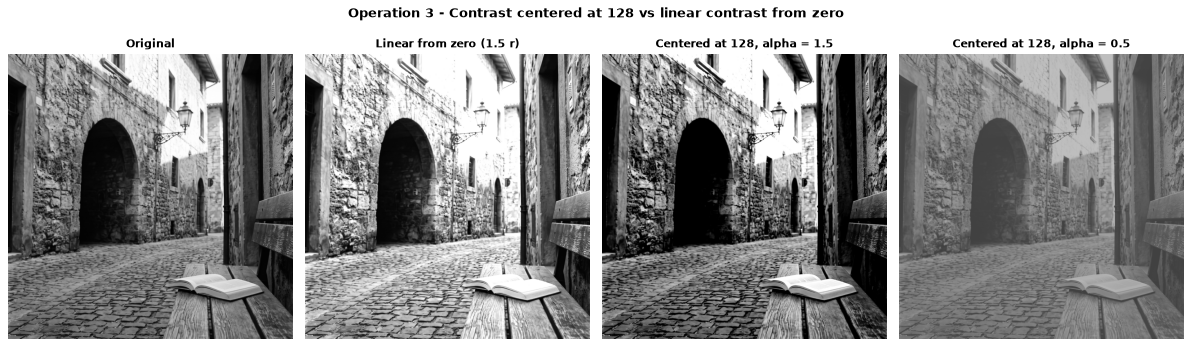

Image          | Mean   | Std-dev | Min | Max | % pixels = 0 | % pixels = 255
---------------+--------+---------+-----+-----+--------------+---------------
Original       | 107.27 | 66.41   | 0   | 255 | 0.01         | 0.39          
Linear 1.5r    | 149.87 | 81.95   | 0   | 255 | 0.01         | 16.25         
Centered a=1.5 | 100.31 | 82.61   | 0   | 255 | 20.78        | 8.20          
Centered a=0.5 | 117.38 | 33.21   | 64  | 191 | 0.00         | 0.00          



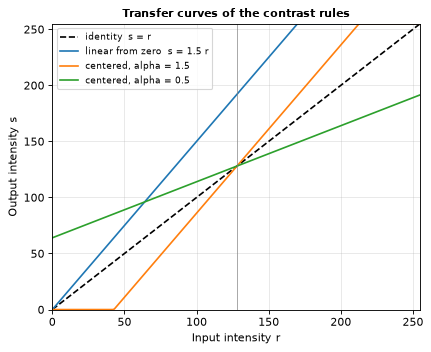

In [9]:
def centered_contrast(img, alpha, pivot=128):
    out = (img.astype(np.float64) - pivot) * alpha + pivot
    return np.clip(out, 0, 255).astype(np.uint8)

centered_15 = centered_contrast(original, 1.5)
centered_05 = centered_contrast(original, 0.5)

show_images([original, linear, centered_15, centered_05],
            ["Original", "Linear from zero (1.5 r)", "Centered at 128, alpha = 1.5", "Centered at 128, alpha = 0.5"],
            "Operation 3 - Contrast centered at 128 vs linear contrast from zero", ncols=4)

print_stats([("Original", original), ("Linear 1.5r", linear),
             ("Centered a=1.5", centered_15), ("Centered a=0.5", centered_05)])

# Transfer curves: output vs input for every rule
r = np.arange(256)
plt.figure(figsize=(5.5, 4.5))
plt.plot(r, r, "k--", label="identity  s = r")
plt.plot(r, np.clip(1.5 * r, 0, 255), label="linear from zero  s = 1.5 r")
plt.plot(r, np.clip((r - 128) * 1.5 + 128, 0, 255), label="centered, alpha = 1.5")
plt.plot(r, np.clip((r - 128) * 0.5 + 128, 0, 255), label="centered, alpha = 0.5")
plt.axvline(128, color="gray", lw=0.6)
plt.xlim(0, 255); plt.ylim(0, 255)
plt.xlabel("Input intensity r"); plt.ylabel("Output intensity s")
plt.title("Transfer curves of the contrast rules"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Observations — centered contrast vs contrast from zero**
- **α = 1.5 centered at 128:** the overall brightness stays close to the original (mean 100.31 vs 107.27) because mid-gray is fixed, but the spread grows (std-dev 82.61). Because this photograph has many pixels below 128, 20.78 % of the image is pushed to pure black and 8.20 % to pure white — both ends are clipped.
- **α = 0.5 centered at 128:** contrast is compressed to the range 64–191 (std-dev 33.21); the picture looks flat and gray, but nothing is clipped (0 % at 0 and 255).
- **Versus linear contrast from zero:** the linear rule (mean 149.87) mixed a brightness increase with the contrast increase, whereas the centered rule changes only the *separation* of dark and light tones around 128. This is the practical difference between **brightness (shift)** and **contrast (scale/spread)**.

---
## 4. Image negative
Rule: &nbsp; **s = 255 − r**. Because r is already in 0–255, the result is always in 0–255 (no clipping needed).

### Dry run 4 — pixels [30, 80, 128, 180, 240]
| r | 255 − r | apply negative again: 255 − (255 − r) | equals original? |
|---|---|---|---|
| 30  | **225** | 30  | yes |
| 80  | **175** | 80  | yes |
| 128 | **127** | 128 | yes |
| 180 | **75**  | 180 | yes |
| 240 | **15**  | 240 | yes |

In [10]:
hand_neg   = [225, 175, 127, 75, 15]
hand_twice = [30, 80, 128, 180, 240]

neg  = 255 - P            # uint8 is safe: 255 - r is always within 0-255 (never negative), so no overflow and no clipping
twice = 255 - neg

print_table(["r", "255 - r", "255 - (255 - r)", "equals original?"],
            [[p, n, t, p == t] for p, n, t in zip(P, neg, twice)],
            "Dry run 4 - image negative (computed in Python)")
verify("negative values",        hand_neg,   neg)
verify("negative applied twice", hand_twice, twice)
verify("double negative equals original", P, twice)

Dry run 4 - image negative (computed in Python)
r   | 255 - r | 255 - (255 - r) | equals original?
----+---------+-----------------+-----------------
30  | 225     | 30              | True            
80  | 175     | 80              | True            
128 | 127     | 128             | True            
180 | 75      | 180             | True            
240 | 15      | 240             | True            

✔ MATCH    negative values
✔ MATCH    negative applied twice
✔ MATCH    double negative equals original


**Verification:** 255 − r and the double negative match Python. Applying the negative twice returns exactly [30, 80, 128, 180, 240], so the negative is a **lossless, reversible** transformation (an involution), unlike the clipped operations.

### Image task 4 — image negative

Double negative equals the original image: True


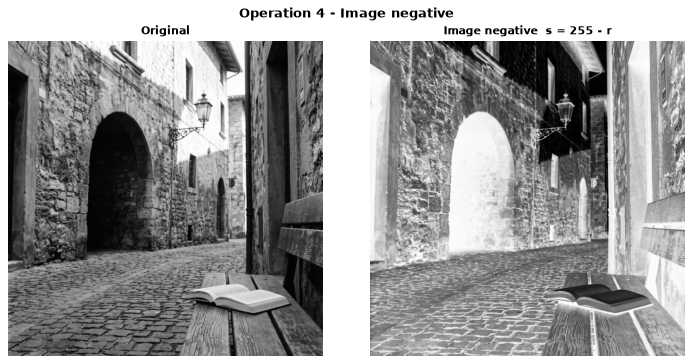

Image    | Mean   | Std-dev | Min | Max | % pixels = 0 | % pixels = 255
---------+--------+---------+-----+-----+--------------+---------------
Original | 107.27 | 66.41   | 0   | 255 | 0.01         | 0.39          
Negative | 147.73 | 66.41   | 0   | 255 | 0.39         | 0.01          



In [11]:
negative = 255 - original      # uint8 is safe here: 255 - r always stays within 0-255, so no widening or clipping is needed
print("Double negative equals the original image:", np.array_equal(255 - negative, original))

show_images([original, negative], ["Original", "Image negative  s = 255 - r"],
            "Operation 4 - Image negative")
print_stats([("Original", original), ("Negative", negative)])

**Observations — image negative**
- The mean becomes 147.73 = 255 − 107.27 and the std-dev is unchanged (66.41): the negative only flips the tonal order, it does not change contrast. Applying it twice returns the original array exactly.
- **When it helps inspection:** it is useful when small bright details are embedded in large dark areas, for example faint bright structures in a dark X-ray/film scan. In the negative they appear as darker marks on a lighter background, which the eye can often judge more easily. In this photograph the very dark archway interior (mean about 22) becomes a near-white area in which its faint stone detail appears as slightly darker marks.

---
## 5. Gamma correction
Rule: &nbsp; **s = 255 · (r / 255)^γ** (convention used in this lab: γ < 1 brightens, γ > 1 darkens). &nbsp; γ = 0.5 and γ = 2.0.

### Dry run 5 — pixels [0, 64, 128, 192, 255]
Full precision is kept in every intermediate step; **only the final output is truncated**.

**gamma = 0.5**

| r | r/255 | (r/255)^0.5 | x 255 (full precision) | final (truncated) |
|---|---|---|---|---|
| 0 | 0.000000 | 0.000000 | 0.0000 | **0** |
| 64 | 0.250980 | 0.500979 | 127.7498 | **127** |
| 128 | 0.501961 | 0.708492 | 180.6654 | **180** |
| 192 | 0.752941 | 0.867722 | 221.2691 | **221** |
| 255 | 1.000000 | 1.000000 | 255.0000 | **255** |

**gamma = 2.0**

| r | r/255 | (r/255)^2.0 | x 255 (full precision) | final (truncated) |
|---|---|---|---|---|
| 0 | 0.000000 | 0.000000 | 0.0000 | **0** |
| 64 | 0.250980 | 0.062991 | 16.0627 | **16** |
| 128 | 0.501961 | 0.251965 | 64.2510 | **64** |
| 192 | 0.752941 | 0.566920 | 144.5647 | **144** |
| 255 | 1.000000 | 1.000000 | 255.0000 | **255** |

In [12]:
G = np.array([0, 64, 128, 192, 255], dtype=np.uint8)
hand_g = {0.5: [0, 127, 180, 221, 255], 2.0: [0, 16, 64, 144, 255]}

for g in (0.5, 2.0):
    norm   = G.astype(np.float64) / 255.0           # step 1: normalise to 0-1
    power  = np.power(norm, g)                      # step 2: raise to gamma
    scaled = 255.0 * power                          # step 3: scale back to 0-255 (full precision)
    final5 = np.clip(scaled, 0, 255).astype(np.uint8)   # step 4: clip + TRUNCATE only here
    print_table(["r", "r/255", f"(r/255)^{g}", "x 255 (full precision)", "final uint8 (truncated)"],
                [[a, f"{b:.6f}", f"{c:.6f}", f"{d:.4f}", e] for a, b, c, d, e in zip(G, norm, power, scaled, final5)],
                f"Dry run 5 - gamma = {g}")
    verify(f"gamma={g}: final uint8", hand_g[g], final5)
    print()

# Comparison with the rounded slide example (gamma = 0.5)
slide_rounded = [0, 128, 181, 221, 255]
ours          = list(np.clip(255 * np.power(G / 255.0, 0.5), 0, 255).astype(np.uint8))
print_table(["r", "slide (rounded)", "this lab (truncated)", "difference"],
            [[a, b, c, b - c] for a, b, c in zip(G, slide_rounded, ours)],
            "Difference from the rounded slide example (gamma = 0.5)")

Dry run 5 - gamma = 0.5
r   | r/255    | (r/255)^0.5 | x 255 (full precision) | final uint8 (truncated)
----+----------+-------------+------------------------+------------------------
0   | 0.000000 | 0.000000    | 0.0000                 | 0                      
64  | 0.250980 | 0.500979    | 127.7498               | 127                    
128 | 0.501961 | 0.708492    | 180.6654               | 180                    
192 | 0.752941 | 0.867722    | 221.2691               | 221                    
255 | 1.000000 | 1.000000    | 255.0000               | 255                    

✔ MATCH    gamma=0.5: final uint8

Dry run 5 - gamma = 2.0
r   | r/255    | (r/255)^2.0 | x 255 (full precision) | final uint8 (truncated)
----+----------+-------------+------------------------+------------------------
0   | 0.000000 | 0.000000    | 0.0000                 | 0                      
64  | 0.250980 | 0.062991    | 16.0627                | 16                     
128 | 0.501961 | 0.251965    | 64.25

**Verification:** the final truncated outputs for γ = 0.5 → [0, 127, 180, 221, 255] and γ = 2.0 → [0, 16, 64, 144, 255] match Python. Note that 0 and 255 stay fixed for both γ (0^γ = 0 and 1^γ = 1).

**Difference from the rounded slide example (γ = 0.5):** the slide shows 128 for r = 64 and 181 for r = 128, while this dry run gives **127 and 180**. The difference comes only from the final step. The rounded slide example rounds the result to the nearest integer (127.7498 → 128, 180.6654 → 181), whereas this lab keeps full precision in every intermediate step and **truncates** only the final value to uint8 (127.7498 → 127, 180.6654 → 180), so those two outputs are one level lower. Rounding the intermediate values would not change this. For r = 192 (221.2691) both methods give 221, and r = 0 and r = 255 are identical.

### Image task 5 — gamma γ = 0.5 and γ = 2.0

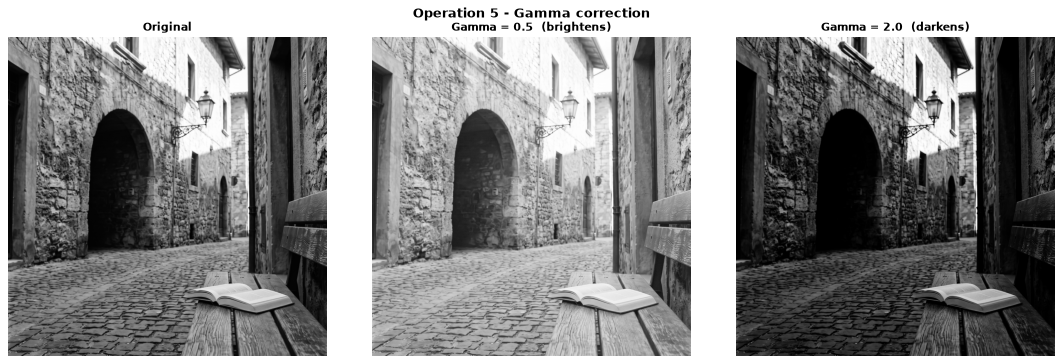

Dark region = pixels with original r < 64  (29.5% of the image)
Image     | Mean intensity inside the dark region
----------+--------------------------------------
Original  | 29.48                                
Gamma 0.5 | 80.41                                
Gamma 2.0 | 4.44                                 



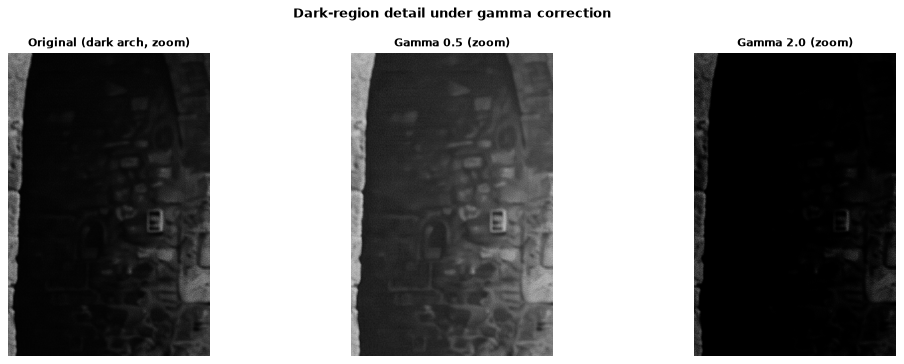

0 and 255 under gamma 0.5 : [  0 255]
0 and 255 under gamma 2.0 : [  0 255]
Image check, gamma 0.5: all 431 black pixels stay 0 -> True;  all 16500 white pixels stay 255 -> True
Image check, gamma 2.0: all 431 black pixels stay 0 -> True;  all 16500 white pixels stay 255 -> True


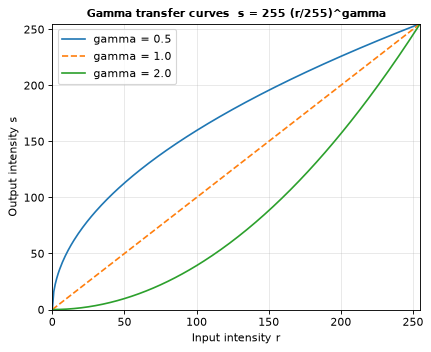

Image     | Mean   | Std-dev | Min | Max | % pixels = 0 | % pixels = 255
----------+--------+---------+-----+-----+--------------+---------------
Original  | 107.27 | 66.41   | 0   | 255 | 0.01         | 0.39          
Gamma 0.5 | 154.40 | 57.83   | 0   | 255 | 0.01         | 0.39          
Gamma 2.0 | 62.00  | 64.87   | 0   | 255 | 9.76         | 0.39          



In [13]:
def gamma_correct(img, g):
    norm = img.astype(np.float64) / 255.0
    return np.clip(255.0 * np.power(norm, g), 0, 255).astype(np.uint8)

gamma_05 = gamma_correct(original, 0.5)
gamma_20 = gamma_correct(original, 2.0)

show_images([original, gamma_05, gamma_20],
            ["Original", "Gamma = 0.5  (brightens)", "Gamma = 2.0  (darkens)"],
            "Operation 5 - Gamma correction")

# ---- effect on DARK regions: pixels with r < 64 in the original ----
dark_region = original < 64
print(f"Dark region = pixels with original r < 64  ({100 * dark_region.mean():.1f}% of the image)")
print_table(["Image", "Mean intensity inside the dark region"],
            [["Original", f"{original[dark_region].mean():.2f}"],
             ["Gamma 0.5", f"{gamma_05[dark_region].mean():.2f}"],
             ["Gamma 2.0", f"{gamma_20[dark_region].mean():.2f}"]])

# ---- zoom on the dark archway interior ----
dark_crop = (slice(660, 1260), slice(500, 900))    # rows, cols of the dark archway (2048 x 2048 image)
show_images([original[dark_crop], gamma_05[dark_crop], gamma_20[dark_crop]],
            ["Original (dark arch, zoom)", "Gamma 0.5 (zoom)", "Gamma 2.0 (zoom)"],
            "Dark-region detail under gamma correction")

# ---- confirm that 0 and 255 stay fixed ----
fixed_test = np.array([0, 255], dtype=np.uint8)
print("0 and 255 under gamma 0.5 :", gamma_correct(fixed_test, 0.5))
print("0 and 255 under gamma 2.0 :", gamma_correct(fixed_test, 2.0))
for name, out in (("0.5", gamma_05), ("2.0", gamma_20)):
    ok0   = np.all(out[original == 0] == 0)
    ok255 = np.all(out[original == 255] == 255)
    print(f"Image check, gamma {name}: all {np.sum(original == 0)} black pixels stay 0 -> {ok0};  "
          f"all {np.sum(original == 255)} white pixels stay 255 -> {ok255}")
    assert ok0 and ok255

# ---- transfer curves ----
r = np.arange(256)
plt.figure(figsize=(5.5, 4.5))
for g, st in ((0.5, "-"), (1.0, "--"), (2.0, "-")):
    plt.plot(r, 255 * (r / 255) ** g, st, label=f"gamma = {g}")
plt.xlim(0, 255); plt.ylim(0, 255); plt.grid(alpha=0.3)
plt.xlabel("Input intensity r"); plt.ylabel("Output intensity s")
plt.title("Gamma transfer curves  s = 255 (r/255)^gamma"); plt.legend()
plt.tight_layout(); plt.show()

print_stats([("Original", original), ("Gamma 0.5", gamma_05), ("Gamma 2.0", gamma_20)])

**Observations — gamma correction (convention: s = 255 (r/255)^γ)**
- **γ = 0.5 (< 1) brightens:** inside the dark region (original r < 64, which is 29.5 % of the pixels) the mean rises from 29.48 to 80.41, so the archway interior and shadows become readable; the whole-image mean rises from 107.27 to 154.40. Highlights change little because the curve flattens near 255.
- **γ = 2.0 (> 1) darkens:** the mean inside the dark region falls from 29.48 to 4.44 and 9.76 % of the whole image becomes 0 (values below about 16 map to s < 1 and are truncated to 0), so dark detail is crushed.
- **Fixed points confirmed:** 0 stays 0 and 255 stays 255 for both γ, both on the test array [0, 255] and on all 431 black and 16500 white pixels of the image.
- Unlike brightness (+/− a constant), gamma changes dark and bright tones by different amounts, so it lifts shadows without pushing highlights past 255 — no clipping is needed. (Some libraries use the inverse convention s = 255 (r/255)^(1/γ), where γ > 1 brightens; this lab uses the formula above.)

---
## 6. Grayscale histogram
### Dry run 6 — A = [[0, 50, 50, 100], [100, 150, 200, 255]]
Total pixels = 2 × 4 = **8**.

| intensity | frequency | probability = frequency / 8 |
|---|---|---|
| 0   | 1 | 1/8 = 0.125 |
| 50  | 2 | 2/8 = 0.250 |
| 100 | 2 | 2/8 = 0.250 |
| 150 | 1 | 1/8 = 0.125 |
| 200 | 1 | 1/8 = 0.125 |
| 255 | 1 | 1/8 = 0.125 |
| **sum** | **8** | **1.000** |

All other intensities (1 … 254 except those above) have frequency 0.

In [14]:
A = np.array([[0, 50, 50, 100],
              [100, 150, 200, 255]], dtype=np.uint8)

hand_vals  = [0, 50, 100, 150, 200, 255]
hand_freq  = [1, 2, 2, 1, 1, 1]
hand_prob  = [0.125, 0.25, 0.25, 0.125, 0.125, 0.125]

counts = hist_counts(A)                       # 256 counts, index = intensity
vals   = np.nonzero(counts)[0]                # intensities that actually occur
freq   = counts[vals]
prob   = freq / A.size

print_table(["intensity", "frequency", "probability"],
            [[v, f, p] for v, f, p in zip(vals, freq, prob)],
            "Dry run 6 - non-zero histogram entries")
print("Total pixel count:", A.size, "| sum of frequencies:", freq.sum(), "| sum of probabilities:", prob.sum())

verify("non-zero intensities", hand_vals, vals)
verify("frequencies",          hand_freq, freq)
verify("probabilities",        hand_prob, prob)
verify("total pixel count",    8, A.size)

# Why a histogram does not show positions: a completely different arrangement gives the SAME histogram
B = np.array([[255, 200, 150, 100],
              [100, 50, 50, 0]], dtype=np.uint8)
print("\nA =\n", A, "\nB (same values, different positions) =\n", B)
print("Histogram of A equals histogram of B:", np.array_equal(hist_counts(A), hist_counts(B)))

Dry run 6 - non-zero histogram entries
intensity | frequency | probability
----------+-----------+------------
0         | 1         | 0.125      
50        | 2         | 0.25       
100       | 2         | 0.25       
150       | 1         | 0.125      
200       | 1         | 0.125      
255       | 1         | 0.125      

Total pixel count: 8 | sum of frequencies: 8 | sum of probabilities: 1.0
✔ MATCH    non-zero intensities
✔ MATCH    frequencies
✔ MATCH    probabilities
✔ MATCH    total pixel count

A =
 [[  0  50  50 100]
 [100 150 200 255]] 
B (same values, different positions) =
 [[255 200 150 100]
 [100  50  50   0]]
Histogram of A equals histogram of B: True


**Verification:** frequencies, probabilities (sum = 1) and the total pixel count of 8 match Python.

**Why a histogram does not show pixel positions:** it only counts *how many* pixels have each intensity. Matrix B contains exactly the same values as A in a completely different arrangement, and the two histograms are identical (`True`). Many different images — even a scrambled version of one image — share one histogram, so the spatial layout cannot be recovered from it.

### Image task 6 — 256-bin histogram of the original image

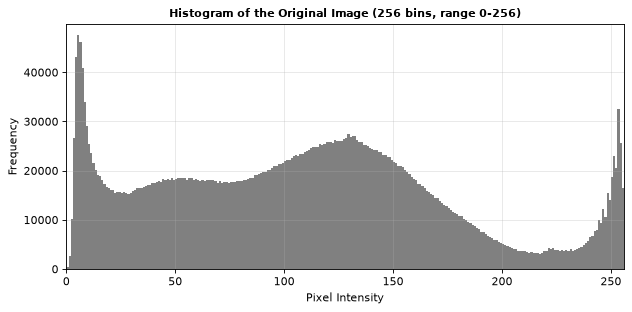

Mean = 107.3, median = 108, std-dev = 66.4
Dark pixels   (0-85)   :  38.9%
Medium pixels (86-170) :  45.2%
Bright pixels (171-255):  15.9%
Most frequent intensity: 5  (47517 pixels)


In [15]:
plt.figure(figsize=(8, 4))
plt.hist(original.ravel(), bins=256, range=(0, 256), color="gray")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Histogram of the Original Image (256 bins, range 0-256)")
plt.xlim(0, 256)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

h = hist_counts(original)
total = original.size
print(f"Mean = {original.mean():.1f}, median = {np.median(original):.0f}, std-dev = {original.std():.1f}")
print(f"Dark pixels   (0-85)   : {100 * h[:86].sum() / total:5.1f}%")
print(f"Medium pixels (86-170) : {100 * h[86:171].sum() / total:5.1f}%")
print(f"Bright pixels (171-255): {100 * h[171:].sum() / total:5.1f}%")
print(f"Most frequent intensity: {h.argmax()}  ({h.max()} pixels)")

**Interpretation of the histogram (two sentences):**
The distribution covers almost the whole 0–255 range: a tall spike at the darkest intensities (peak at 5, the shadowed archway and doorways), a flat shoulder from about 20 to 90 and a broad central hump peaking near 130 (the stone walls and cobbles), a shallow valley around 210–230, and a smaller rise near 250–255 (sky, sunlit wall and book pages). About 39 % of the pixels are dark (0–85), 45 % are medium and only 16 % are bright (171–255), so the image leans moderately dark, which is why gamma and equalization can reveal extra shadow detail.

---
## 7. Global histogram equalization
OpenCV's `cv2.equalizeHist` maps each intensity through the (normalised) cumulative distribution of the image's histogram.

### Dry run 7 — pixels [50, 50, 100, 150]  (N = 4)
| value | frequency | cumulative count | CDF = cum / 4 | 255 × CDF | rounded (.5 up) |
|---|---|---|---|---|---|
| 50  | 2 | 2 | 0.50 | 127.5  | **128** |
| 100 | 1 | 3 | 0.75 | 191.25 | **191** |
| 150 | 1 | 4 | 1.00 | 255    | **255** |

CDFmin = 0.50 (lowest non-zero CDF). Second mapping: 255 × (CDF − 0.5)/(1 − 0.5)

| value | CDF | (CDF − 0.5)/0.5 | × 255 | rounded (.5 up) |
|---|---|---|---|---|
| 50  | 0.50 | 0.0 | 0.0   | **0** |
| 100 | 0.75 | 0.5 | 127.5 | **128** |
| 150 | 1.00 | 1.0 | 255   | **255** |

**Output lists** for the pixel sequence [50, 50, 100, 150]:
- Mapping 1 (255 × CDF): **[128, 128, 191, 255]**
- Mapping 2 (CDFmin-corrected): **[0, 0, 128, 255]**

In [16]:
pix = np.array([50, 50, 100, 150], dtype=np.uint8)
N = pix.size

vals7, freq7 = np.unique(pix, return_counts=True)
cum7  = np.cumsum(freq7)
cdf7  = cum7 / N
cdf_min = cdf7[cdf7 > 0].min()

map1 = round_half_up(255 * cdf7)                                   # 255 x CDF
map2 = round_half_up(255 * (cdf7 - cdf_min) / (1 - cdf_min))       # 255 x (CDF-CDFmin)/(1-CDFmin)

out1 = np.array([dict(zip(vals7, map1))[v] for v in pix])
out2 = np.array([dict(zip(vals7, map2))[v] for v in pix])

print_table(["value", "freq", "cum.count", "CDF", "255*CDF", "mapping 1", "255*(CDF-CDFmin)/(1-CDFmin)", "mapping 2"],
            [[v, f, c, d, 255 * d, m1, 255 * (d - cdf_min) / (1 - cdf_min), m2]
             for v, f, c, d, m1, m2 in zip(vals7, freq7, cum7, cdf7, map1, map2)],
            f"Dry run 7 - CDFmin = {cdf_min}")

verify("frequencies",        [2, 1, 1],            freq7)
verify("cumulative counts",  [2, 3, 4],            cum7)
verify("CDF",                [0.5, 0.75, 1.0],     cdf7)
verify("mapping 1 table",    [128, 191, 255],      map1)
verify("mapping 2 table",    [0, 128, 255],        map2)
verify("output list 1",      [128, 128, 191, 255], out1)
verify("output list 2",      [0, 0, 128, 255],     out2)

print("\nOutput list 1 (255 x CDF)               :", out1.astype(int).tolist())
print("Output list 2 (CDFmin-corrected mapping):", out2.astype(int).tolist())

opencv_out = cv2.equalizeHist(pix.reshape(1, -1)).ravel()          # cv2 needs a 2-D 8-bit array
print("OpenCV cv2.equalizeHist output          :", opencv_out.tolist())
verify("mapping 2 equals OpenCV", out2, opencv_out)

Dry run 7 - CDFmin = 0.5
value | freq | cum.count | CDF  | 255*CDF | mapping 1 | 255*(CDF-CDFmin)/(1-CDFmin) | mapping 2
------+------+-----------+------+---------+-----------+-----------------------------+----------
50    | 2    | 2         | 0.5  | 127.5   | 128.0     | 0.0                         | 0.0      
100   | 1    | 3         | 0.75 | 191.25  | 191.0     | 127.5                       | 128.0    
150   | 1    | 4         | 1.0  | 255.0   | 255.0     | 255.0                       | 255.0    

✔ MATCH    frequencies
✔ MATCH    cumulative counts
✔ MATCH    CDF
✔ MATCH    mapping 1 table
✔ MATCH    mapping 2 table
✔ MATCH    output list 1
✔ MATCH    output list 2

Output list 1 (255 x CDF)               : [128, 128, 191, 255]
Output list 2 (CDFmin-corrected mapping): [0, 0, 128, 255]
OpenCV cv2.equalizeHist output          : [0, 0, 128, 255]
✔ MATCH    mapping 2 equals OpenCV


**Verification:** frequencies [2, 1, 1], cumulative counts [2, 3, 4], CDF [0.50, 0.75, 1.00] and both output lists match Python (127.5 is rounded **up** to 128).

- Mapping 1, 255 × CDF → output **[128, 128, 191, 255]**: the darkest pixel (50) is lifted to 128, because 50 % of the pixels are at or below it.
- Mapping 2, 255 × (CDF − CDFmin)/(1 − CDFmin) → output **[0, 0, 128, 255]**: the lowest occupied value is mapped to 0, so the full 0–255 range is used.
- OpenCV's `cv2.equalizeHist` returned **[0, 0, 128, 255]**, which is identical to the second mapping; OpenCV therefore subtracts the lowest non-zero CDF.

### Image task 7 — `cv2.equalizeHist` on the grayscale image

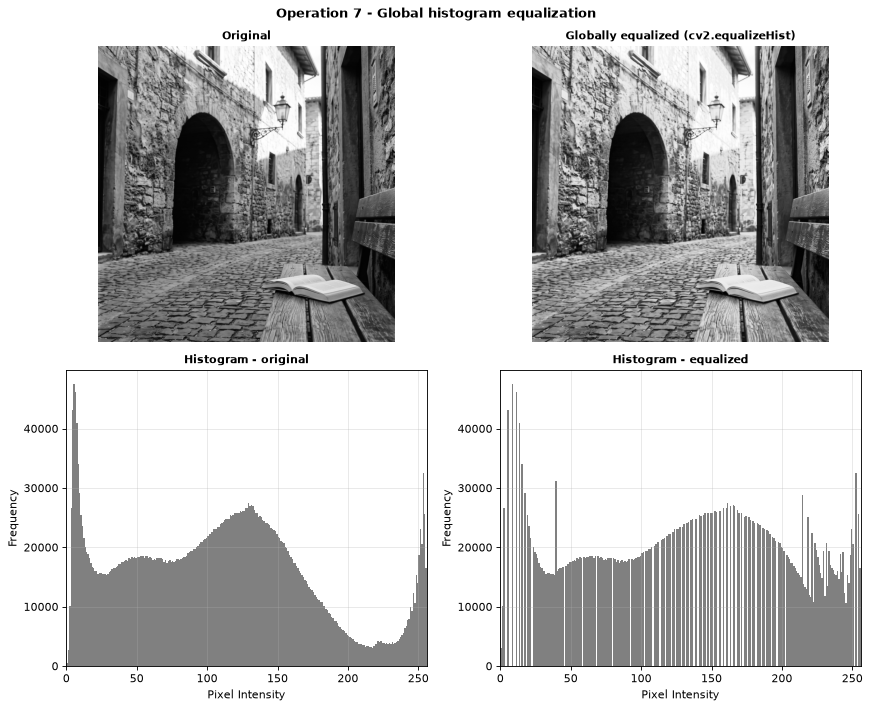

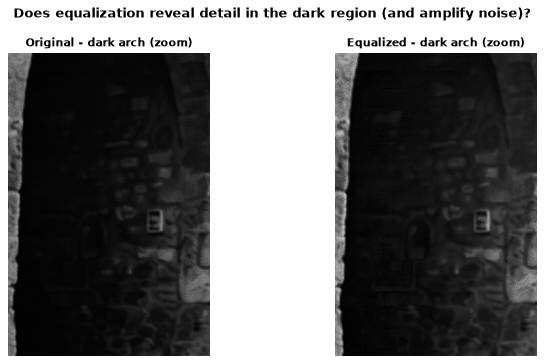

Measure                                  | Original | Equalized
-----------------------------------------+----------+----------
Mean intensity (whole image)             | 107.3    | 128.1    
Std-dev (whole image)                    | 66.4     | 73.5     
Mean intensity inside dark arch crop     | 22.5     | 30.7     
Std-dev inside dark arch crop            | 26.9     | 31.6     
Laplacian variance inside dark arch crop | 449.6    | 753.6    



In [17]:
equalized = cv2.equalizeHist(original)

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, im, t in zip(axes[0], [original, equalized], ["Original", "Globally equalized (cv2.equalizeHist)"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
for ax, im, t in zip(axes[1], [original, equalized], ["Histogram - original", "Histogram - equalized"]):
    ax.hist(im.ravel(), bins=256, range=(0, 256), color="gray")
    ax.set_title(t); ax.set_xlabel("Pixel Intensity"); ax.set_ylabel("Frequency"); ax.set_xlim(0, 256); ax.grid(alpha=0.3)
fig.suptitle("Operation 7 - Global histogram equalization", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

# ---- detail and noise: zoom on the dark archway + numeric proxies ----
show_images([original[dark_crop], equalized[dark_crop]],
            ["Original - dark arch (zoom)", "Equalized - dark arch (zoom)"],
            "Does equalization reveal detail in the dark region (and amplify noise)?")

def lap_var(a):
    """Variance of the Laplacian: higher = stronger fine-scale intensity variation (detail AND noise)."""
    return cv2.Laplacian(a.astype(np.float64), cv2.CV_64F).var()

print_table(["Measure", "Original", "Equalized"],
            [["Mean intensity (whole image)",                 f"{original.mean():.1f}",  f"{equalized.mean():.1f}"],
             ["Std-dev (whole image)",                        f"{original.std():.1f}",   f"{equalized.std():.1f}"],
             ["Mean intensity inside dark arch crop",         f"{original[dark_crop].mean():.1f}", f"{equalized[dark_crop].mean():.1f}"],
             ["Std-dev inside dark arch crop",                f"{original[dark_crop].std():.1f}",  f"{equalized[dark_crop].std():.1f}"],
             ["Laplacian variance inside dark arch crop",     f"{lap_var(original[dark_crop]):.1f}", f"{lap_var(equalized[dark_crop]):.1f}"]])

**Observations — global histogram equalization**
- The equalized histogram is spread much more evenly across 0–255 (with gaps — 49 of the 256 levels are empty — because only 256 levels are redistributed), the mean rises from 107.3 to 128.1 and the std-dev from 66.4 to 73.5.
- **Detail improves** in the dark archway: its mean rises from 22.5 to 30.7 and its std-dev from 26.9 to 31.6, so the stones, the doorbell and the arch edge are easier to see in the zoom.
- **Noise becomes stronger:** the Laplacian variance (fine-scale variation) in that dark crop increases from 449.6 to 753.6 (+68 %), and a faint grid/blocky texture (grain and compression artifacts) becomes slightly more visible in the zoomed equalized archway. The Laplacian variance measures fine-scale variation in general, so it counts real detail and noise together; equalization stretches tiny intensity differences, so it amplifies noise and compression artifacts as well as stone detail.
- Because one global mapping is used, the already bright wall is also pushed brighter (see operation 8), so the improvement in the shadows costs some contrast in the highlights.

---
## 8. CLAHE (Contrast Limited Adaptive Histogram Equalization)
`cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))`. **(8, 8) is the number of tiles** (8 rows × 8 columns), *not* the number of pixels per tile — the tile size depends on the image size.

### Dry run 8 — four-bin histogram [6, 2, 0, 0], absolute bin cap = 4
1. **Clip:** bin 0 has 6 > 4, so it becomes 4 and **excess = 6 − 4 = 2**. Clipped histogram = [4, 2, 0, 0].
2. **Redistribute** the excess equally over the 4 bins: 2 / 4 = **0.5** each → [4.5, 2.5, 0.5, 0.5] (total is still 8; fractions allowed).
3. **New CDF (counts):** 4.5, 7.0, 7.5, 8.0 → **normalised (÷ 8): 0.5625, 0.875, 0.9375, 1.0**.

| bin | original hist | clipped | + 0.5 redistributed | cumulative | new CDF (÷8) | CDF without clipping (÷8) |
|---|---|---|---|---|---|---|
| 0 | 6 | 4 | 4.5 | 4.5 | **0.5625** | 0.75 |
| 1 | 2 | 2 | 2.5 | 7.0 | **0.8750** | 1.00 |
| 2 | 0 | 0 | 0.5 | 7.5 | **0.9375** | 1.00 |
| 3 | 0 | 0 | 0.5 | 8.0 | **1.0000** | 1.00 |

In [18]:
hist8 = np.array([6, 2, 0, 0], dtype=np.float64)
cap = 4.0

hand_clipped = [4, 2, 0, 0]
hand_redis   = [4.5, 2.5, 0.5, 0.5]
hand_cum     = [4.5, 7.0, 7.5, 8.0]
hand_cdf     = [0.5625, 0.875, 0.9375, 1.0]

clipped8 = np.minimum(hist8, cap)                    # step 1: clip every bin at the cap
excess   = (hist8 - clipped8).sum()                  #         total clipped-off count
redis8   = clipped8 + excess / hist8.size            # step 2: spread the excess equally (fractions allowed)
cum8     = np.cumsum(redis8)                         # step 3: cumulative counts
cdf8     = cum8 / cum8[-1]                           #         normalised CDF
cdf8_noclip = np.cumsum(hist8) / hist8.sum()         # CDF of the unclipped histogram, for comparison

print(f"Excess removed by clipping = {excess}  ->  added to each bin = {excess / hist8.size}")
print_table(["bin", "original", "clipped", "redistributed", "cumulative", "new CDF", "CDF w/o clipping"],
            [[i, a, b, c, d, e, f] for i, (a, b, c, d, e, f) in enumerate(zip(hist8, clipped8, redis8, cum8, cdf8, cdf8_noclip))],
            "Dry run 8 - simplified CLAHE on one tile")

verify("clipped histogram",     hand_clipped, clipped8)
verify("redistributed histogram", hand_redis, redis8)
verify("cumulative counts",     hand_cum,     cum8)
verify("new CDF",               hand_cdf,     cdf8)
verify("total count preserved (8)", 8, redis8.sum())

Excess removed by clipping = 2.0  ->  added to each bin = 0.5
Dry run 8 - simplified CLAHE on one tile
bin | original | clipped | redistributed | cumulative | new CDF | CDF w/o clipping
----+----------+---------+---------------+------------+---------+-----------------
0   | 6.0      | 4.0     | 4.5           | 4.5        | 0.5625  | 0.75            
1   | 2.0      | 2.0     | 2.5           | 7.0        | 0.875   | 1.0             
2   | 0.0      | 0.0     | 0.5           | 7.5        | 0.9375  | 1.0             
3   | 0.0      | 0.0     | 0.5           | 8.0        | 1.0     | 1.0             

✔ MATCH    clipped histogram
✔ MATCH    redistributed histogram
✔ MATCH    cumulative counts
✔ MATCH    new CDF
✔ MATCH    total count preserved (8)


**Verification:** clipped histogram [4, 2, 0, 0], redistributed histogram [4.5, 2.5, 0.5, 0.5] and new CDF [0.5625, 0.875, 0.9375, 1.0] match Python; the total count (8) is preserved.

**Effect of clipping:** the first bin's CDF value falls from 0.75 to 0.5625, i.e. the steepest part of the mapping is flattened, which is exactly how the clip limit restricts contrast amplification (and therefore noise amplification) in a nearly uniform region.

**Why neighbouring tile mappings need interpolation:** each tile has its *own* CDF mapping. If every pixel simply used the mapping of the tile that contains it, the same intensity would map to different outputs on two sides of a tile border, producing visible blocky seams. CLAHE therefore **bilinearly interpolates between the mappings of the neighbouring tiles**, so the output changes smoothly across borders.

*Note:* this is a simplified model — OpenCV redistributes integer counts, and the absolute cap of 4 used here is not the same thing as OpenCV's `clipLimit` parameter.

### Image task 8 — CLAHE (clipLimit = 2.0, tileGridSize = (8, 8)) vs global equalization

tileGridSize=(8, 8) -> 8 x 8 = 64 tiles; for this 2048 x 2048 image each tile is 256 x 256 pixels.


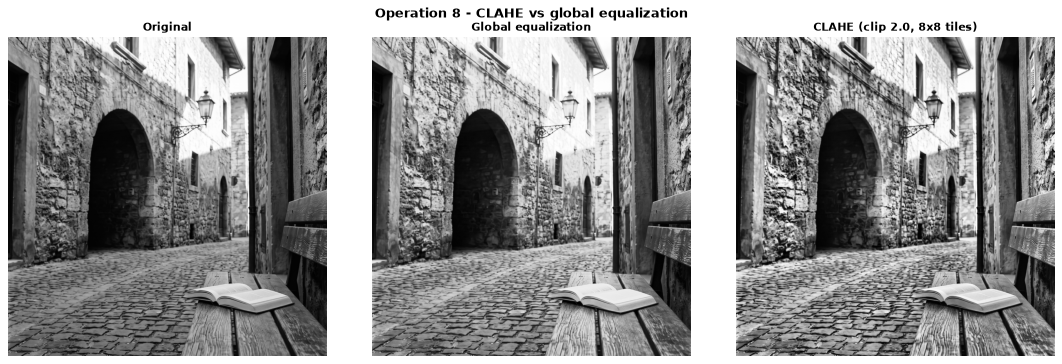

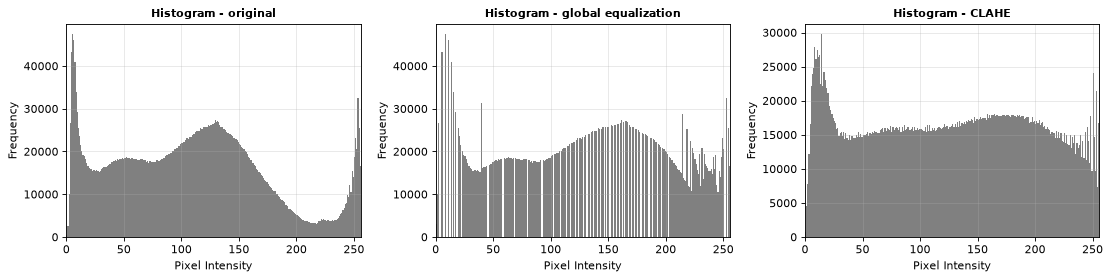

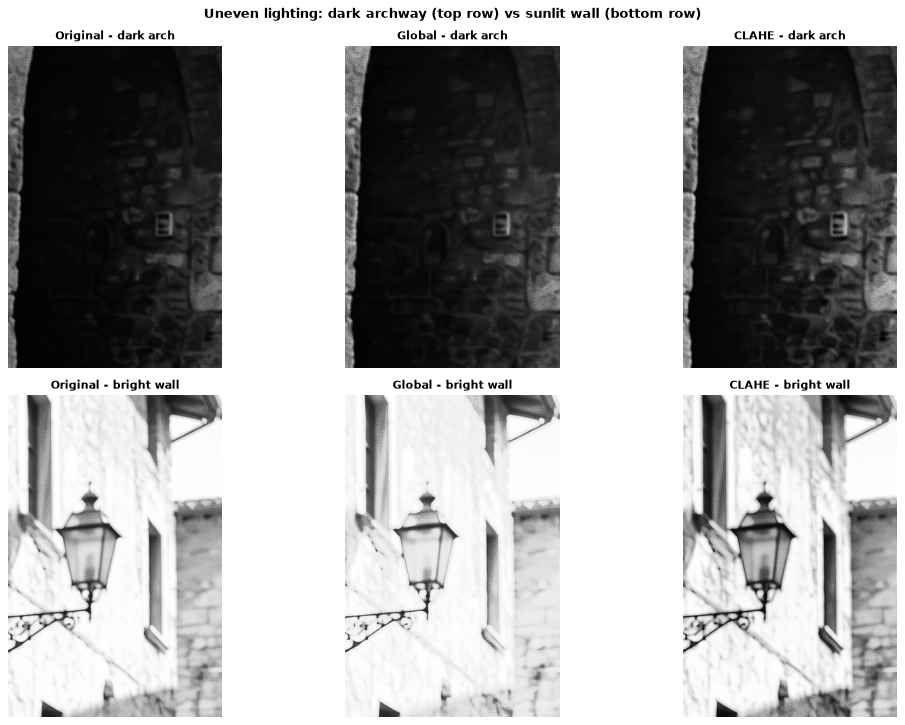

Region / measure                 | Original | Global equalization | CLAHE 
---------------------------------+----------+---------------------+-------
Dark arch - mean                 | 22.5     | 30.7                | 37.7  
Dark arch - std-dev              | 26.9     | 31.6                | 37.7  
Bright wall - mean               | 211.2    | 223.0               | 192.8 
Bright wall - std-dev            | 55.1     | 46.9                | 66.2  
Whole image - Laplacian variance | 2188.4   | 3684.7              | 5876.4



In [19]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
local = clahe.apply(original)

print(f"tileGridSize=(8, 8) -> 8 x 8 = 64 tiles; for this {height} x {width} image each tile is "
      f"{height // 8} x {width // 8} pixels.")

show_images([original, equalized, local],
            ["Original", "Global equalization", "CLAHE (clip 2.0, 8x8 tiles)"],
            "Operation 8 - CLAHE vs global equalization")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, im, t in zip(axes, [original, equalized, local], ["Histogram - original", "Histogram - global equalization", "Histogram - CLAHE"]):
    ax.hist(im.ravel(), bins=256, range=(0, 256), color="gray")
    ax.set_title(t); ax.set_xlabel("Pixel Intensity"); ax.set_ylabel("Frequency"); ax.set_xlim(0, 256); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ---- uneven lighting: compare a DARK region and a BRIGHT region ----
bright_crop = (slice(160, 760), slice(1120, 1520))   # sunlit wall with the lantern (2048 x 2048 image)
show_images([original[dark_crop], equalized[dark_crop], local[dark_crop],
             original[bright_crop], equalized[bright_crop], local[bright_crop]],
            ["Original - dark arch", "Global - dark arch", "CLAHE - dark arch",
             "Original - bright wall", "Global - bright wall", "CLAHE - bright wall"],
            "Uneven lighting: dark archway (top row) vs sunlit wall (bottom row)", ncols=3)

print_table(["Region / measure", "Original", "Global equalization", "CLAHE"],
            [["Dark arch - mean",        f"{original[dark_crop].mean():.1f}",  f"{equalized[dark_crop].mean():.1f}",  f"{local[dark_crop].mean():.1f}"],
             ["Dark arch - std-dev",     f"{original[dark_crop].std():.1f}",   f"{equalized[dark_crop].std():.1f}",   f"{local[dark_crop].std():.1f}"],
             ["Bright wall - mean",      f"{original[bright_crop].mean():.1f}", f"{equalized[bright_crop].mean():.1f}", f"{local[bright_crop].mean():.1f}"],
             ["Bright wall - std-dev",   f"{original[bright_crop].std():.1f}",  f"{equalized[bright_crop].std():.1f}",  f"{local[bright_crop].std():.1f}"],
             ["Whole image - Laplacian variance", f"{lap_var(original):.1f}", f"{lap_var(equalized):.1f}", f"{lap_var(local):.1f}"]])

**Observations — CLAHE vs global equalization**
- **Tiles, not pixels:** `tileGridSize=(8, 8)` means 8 × 8 = 64 tiles; for this 2048 × 2048 image each tile is 256 × 256 pixels (a different image size would give different tile sizes).
- **Dark region (arch):** both methods lift it (mean 22.5 → 30.7 global, 37.7 CLAHE), but CLAHE gives more local contrast (std-dev 37.7 vs 31.6), so the stonework is clearer.
- **Bright region (sunlit wall):** global equalization pushes the wall brighter (mean 211.2 → 223.0) and *reduces* its contrast (std-dev 55.1 → 46.9), giving a washed-out look. CLAHE keeps the wall darker (mean 192.8) and *increases* its contrast (std-dev 66.2), so the lantern and wall texture stay crisp. This shows why local enhancement handles **uneven lighting** better.
- **Cost:** the whole-image Laplacian variance rises from 2188.4 (original) to 3684.7 (global) and 5876.4 (CLAHE), so CLAHE emphasises fine texture most — and with it grain/noise in the dark areas — which is why the clip limit exists.

---
## 9. Fixed binary thresholding
Rule: &nbsp; **output = 255 if r > T, otherwise 0** (`cv2.THRESH_BINARY`). A pixel equal to T becomes 0.

### Dry run 9 — pixels [0, 80, 127, 128, 180, 255]
| r | r > 127 ? | output (T = 127) | r > 180 ? | output (T = 180) |
|---|---|---|---|---|
| 0   | no  | **0**   | no  | **0** |
| 80  | no  | **0**   | no  | **0** |
| 127 | no  | **0**   | no  | **0** |
| 128 | yes | **255** | no  | **0** |
| 180 | yes | **255** | no (180 > 180 is false) | **0** |
| 255 | yes | **255** | yes | **255** |

White pixels: **3** for T = 127 and **1** for T = 180.

In [20]:
T9 = np.array([0, 80, 127, 128, 180, 255], dtype=np.uint8)
hand_t127 = [0, 0, 0, 255, 255, 255]
hand_t180 = [0, 0, 0, 0, 0, 255]

out127 = np.where(T9 > 127, 255, 0).astype(np.uint8)
out180 = np.where(T9 > 180, 255, 0).astype(np.uint8)

print_table(["r", "r > 127 ?", "T=127 output", "r > 180 ?", "T=180 output"],
            [[r_, r_ > 127, a, r_ > 180, b] for r_, a, b in zip(T9, out127, out180)],
            "Dry run 9 - fixed thresholds (computed in Python)")

verify("T = 127 outputs", hand_t127, out127)
verify("T = 180 outputs", hand_t180, out180)
print("White-pixel count  T=127:", int((out127 == 255).sum()), "  T=180:", int((out180 == 255).sum()))

# cross-check with OpenCV
_, cv127 = cv2.threshold(T9.reshape(1, -1), 127, 255, cv2.THRESH_BINARY)
_, cv180 = cv2.threshold(T9.reshape(1, -1), 180, 255, cv2.THRESH_BINARY)
verify("OpenCV matches hand result (T=127)", hand_t127, cv127.ravel())
verify("OpenCV matches hand result (T=180)", hand_t180, cv180.ravel())

Dry run 9 - fixed thresholds (computed in Python)
r   | r > 127 ? | T=127 output | r > 180 ? | T=180 output
----+-----------+--------------+-----------+-------------
0   | False     | 0            | False     | 0           
80  | False     | 0            | False     | 0           
127 | False     | 0            | False     | 0           
128 | True      | 255          | False     | 0           
180 | True      | 255          | False     | 0           
255 | True      | 255          | True      | 255         

✔ MATCH    T = 127 outputs
✔ MATCH    T = 180 outputs
White-pixel count  T=127: 3   T=180: 1
✔ MATCH    OpenCV matches hand result (T=127)
✔ MATCH    OpenCV matches hand result (T=180)


**Verification:** both output lists match Python and OpenCV. **T = 127 gives 3 white pixels (128, 180, 255); T = 180 gives only 1 (255).** Raising the threshold classifies fewer pixels as white. Pixels equal to the threshold (127 for T = 127, and 180 for T = 180) stay 0 because the rule is r > T, not r ≥ T.

### Image task 9 — fixed threshold T = 127

Threshold used          : 127.0
Unique output values    : [  0 255]
White pixels (255)      : 1593882  (38.00%)
Black pixels (0)        : 2600422  (62.00%)


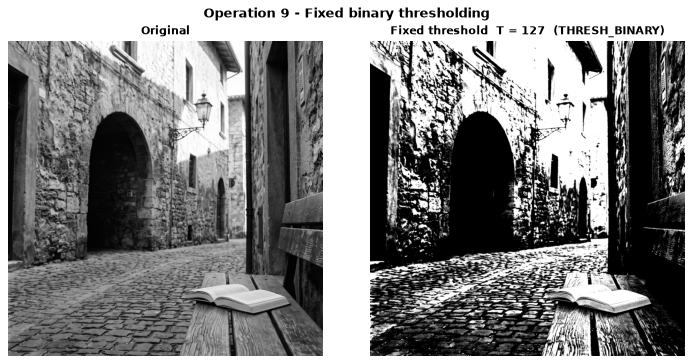

In [21]:
T_fixed = 127
ret_fixed, binary_fixed = cv2.threshold(original, T_fixed, 255, cv2.THRESH_BINARY)

print("Threshold used          :", ret_fixed)
print("Unique output values    :", np.unique(binary_fixed))
print(f"White pixels (255)      : {np.sum(binary_fixed == 255)}  ({100 * np.mean(binary_fixed == 255):.2f}%)")
print(f"Black pixels (0)        : {np.sum(binary_fixed == 0)}  ({100 * np.mean(binary_fixed == 0):.2f}%)")

show_images([original, binary_fixed], ["Original", f"Fixed threshold  T = {T_fixed}  (THRESH_BINARY)"],
            "Operation 9 - Fixed binary thresholding")

**Observations — fixed threshold T = 127**
- Unique output values: **[0, 255]** only, as required for a binary image.
- 38.00 % of the pixels become white and 62.00 % black. The sunlit walls, sky and book pages become white, while the archway, doorways, cobble gaps and shaded wall become black, so most mid-gray texture is lost.
- A single global threshold ignores the lighting: anything in shadow is forced to black regardless of how much detail it contains.

---
## 10. Otsu thresholding
Otsu's method tries every threshold T, splits the pixels into class 0 (r ≤ T) and class 1 (r > T), and picks the T that maximises the between-class variance **w₀ · w₁ · (μ₀ − μ₁)²**.

### Dry run 10 — pixels [0, 1, 4, 5] (no rescaling)
| T | class 0 (r ≤ T) | class 1 (r > T) | w₀ | w₁ | μ₀ | μ₁ | w₀w₁(μ₀−μ₁)² |
|---|---|---|---|---|---|---|---|
| 0 | {0}       | {1, 4, 5} | 1/4 | 3/4 | 0     | 10/3 ≈ 3.333 | (3/16)(100/9) ≈ **2.0833** |
| 1 | {0, 1}    | {4, 5}    | 1/2 | 1/2 | 0.5   | 4.5          | (1/4)(16) = **4.0** |
| 2 | {0, 1}    | {4, 5}    | 1/2 | 1/2 | 0.5   | 4.5          | **4.0** |
| 3 | {0, 1}    | {4, 5}    | 1/2 | 1/2 | 0.5   | 4.5          | **4.0** |
| 4 | {0, 1, 4} | {5}       | 3/4 | 1/4 | 5/3 ≈ 1.667 | 5      | (3/16)(100/9) ≈ **2.0833** |

The maximum (4.0) is tied for T = 1, 2, 3 → choose the **smallest: T = 1**.
Mask with r > 1: pixels 0 → 0, 1 → 0, 4 → 255, 5 → 255, i.e. **[0, 0, 255, 255]**.

In [22]:
pix10 = np.array([0, 1, 4, 5], dtype=np.uint8)

rows, scores = [], []
for T in range(0, 5):
    c0 = pix10[pix10 <= T].astype(np.float64)        # class 0: r <= T
    c1 = pix10[pix10 >  T].astype(np.float64)        # class 1: r >  T
    w0, w1   = len(c0) / pix10.size, len(c1) / pix10.size
    mu0, mu1 = c0.mean(), c1.mean()
    score = w0 * w1 * (mu0 - mu1) ** 2
    scores.append(score)
    rows.append([T, c0.astype(int).tolist(), c1.astype(int).tolist(), w0, w1, f"{mu0:.4f}", f"{mu1:.4f}", f"{score:.4f}"])

print_table(["T", "class 0", "class 1", "w0", "w1", "mu0", "mu1", "w0*w1*(mu0-mu1)^2"], rows,
            "Dry run 10 - between-class variance for every T")

scores = np.array(scores)
verify("between-class variances", [25/12, 4.0, 4.0, 4.0, 25/12], scores)

best_T = min(T for T in range(5) if np.isclose(scores[T], scores.max()))    # smallest T among tied maxima
mask10 = np.where(pix10 > best_T, 255, 0).astype(np.uint8)
print(f"Maximum score = {scores.max():.4f}; tied at T = {[T for T in range(5) if np.isclose(scores[T], scores.max())]}; chosen (smallest) T = {best_T}")
print("Predicted mask:", mask10.tolist())

verify("chosen T",         1, best_T)
verify("predicted mask",   [0, 0, 255, 255], mask10)

otsu_T10, otsu_mask10 = cv2.threshold(pix10.reshape(1, -1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("OpenCV Otsu threshold:", otsu_T10, "| OpenCV mask:", otsu_mask10.ravel().tolist())
verify("OpenCV threshold equals prediction", best_T, otsu_T10)
verify("OpenCV mask equals prediction", mask10, otsu_mask10.ravel())

Dry run 10 - between-class variance for every T
T | class 0   | class 1   | w0   | w1   | mu0    | mu1    | w0*w1*(mu0-mu1)^2
--+-----------+-----------+------+------+--------+--------+------------------
0 | [0]       | [1, 4, 5] | 0.25 | 0.75 | 0.0000 | 3.3333 | 2.0833           
1 | [0, 1]    | [4, 5]    | 0.5  | 0.5  | 0.5000 | 4.5000 | 4.0000           
2 | [0, 1]    | [4, 5]    | 0.5  | 0.5  | 0.5000 | 4.5000 | 4.0000           
3 | [0, 1]    | [4, 5]    | 0.5  | 0.5  | 0.5000 | 4.5000 | 4.0000           
4 | [0, 1, 4] | [5]       | 0.75 | 0.25 | 1.6667 | 5.0000 | 2.0833           

✔ MATCH    between-class variances
Maximum score = 4.0000; tied at T = [1, 2, 3]; chosen (smallest) T = 1
Predicted mask: [0, 0, 255, 255]
✔ MATCH    chosen T
✔ MATCH    predicted mask
OpenCV Otsu threshold: 1.0 | OpenCV mask: [0, 0, 255, 255]
✔ MATCH    OpenCV threshold equals prediction
✔ MATCH    OpenCV mask equals prediction


**Verification:** all between-class variances match Python, the maximum (4.0) occurs for T = 1, 2 and 3, and the smallest tied T is **1**. The predicted mask **[0, 0, 255, 255]** and the threshold **1** are identical to the values returned by OpenCV. T = 1, 2 and 3 produce the same split of the data (no pixels have the values 2 or 3), so they tie.

### Image task 10 — Otsu (`cv2.THRESH_BINARY + cv2.THRESH_OTSU`) vs the fixed threshold

Threshold returned by Otsu: 106.0   (fixed threshold was 127)
Unique output values      : [  0 255]
White pixels  fixed: 38.00%   Otsu: 50.58%
Pixels where the two masks differ: 527757 (12.58%)  -> agreement 87.42%


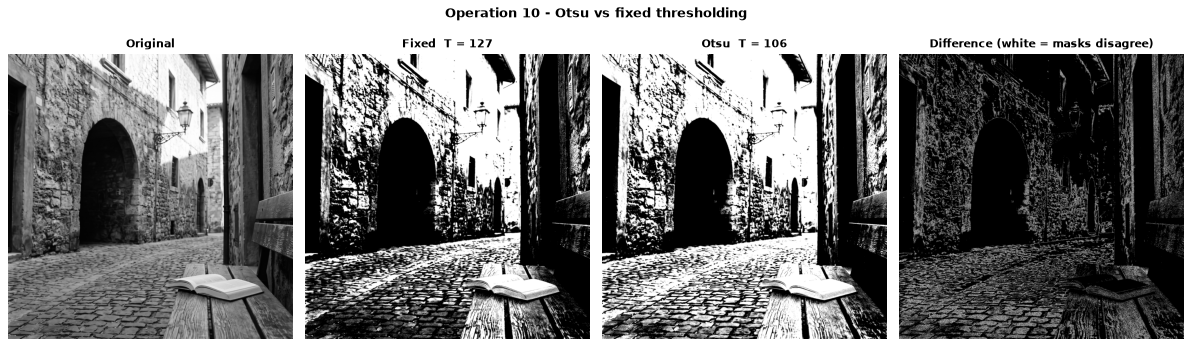

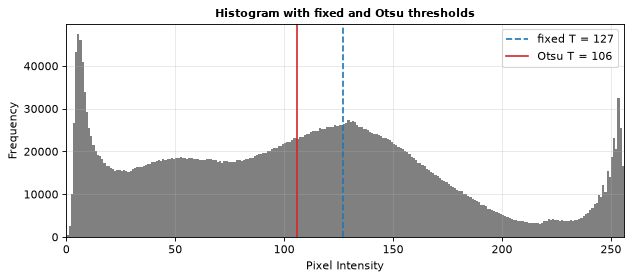

In [23]:
otsu_T, binary_otsu = cv2.threshold(original, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print(f"Threshold returned by Otsu: {otsu_T}   (fixed threshold was {T_fixed})")
print("Unique output values      :", np.unique(binary_otsu))

diff_mask = cv2.absdiff(binary_fixed, binary_otsu)          # 255 where the two masks disagree
n_diff = int(np.count_nonzero(diff_mask))
print(f"White pixels  fixed: {100 * np.mean(binary_fixed == 255):.2f}%   Otsu: {100 * np.mean(binary_otsu == 255):.2f}%")
print(f"Pixels where the two masks differ: {n_diff} ({100 * n_diff / original.size:.2f}%)  -> agreement {100 - 100 * n_diff / original.size:.2f}%")

show_images([original, binary_fixed, binary_otsu, diff_mask],
            ["Original", f"Fixed  T = {T_fixed}", f"Otsu  T = {otsu_T:.0f}", "Difference (white = masks disagree)"],
            "Operation 10 - Otsu vs fixed thresholding", ncols=4)

plt.figure(figsize=(8, 3.6))
plt.hist(original.ravel(), bins=256, range=(0, 256), color="gray")
plt.axvline(T_fixed, color="tab:blue", ls="--", label=f"fixed T = {T_fixed}")
plt.axvline(otsu_T, color="tab:red", ls="-", label=f"Otsu T = {otsu_T:.0f}")
plt.xlabel("Pixel Intensity"); plt.ylabel("Frequency"); plt.title("Histogram with fixed and Otsu thresholds")
plt.xlim(0, 256); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Observations — Otsu thresholding**
- Otsu returned the threshold **T = 106**, lower than the fixed value 127. Otsu does not look for the mean: it chooses the T that maximises the between-class variance w₀·w₁·(μ₀ − μ₁)². This histogram has a large dark spike near 5, a flat plateau of shadow tones, and a broad mid-tone hump around 100–150; T = 106 splits the darker tones from the brighter tones with the largest separation between the two class means. It happens to lie close to the image mean (107.3), but that is a coincidence of this histogram, not the rule.
- Because T is lower, more pixels are white: 50.58 % compared with 38.00 % for the fixed mask. The two masks disagree on 12.58 % of the pixels (agreement 87.42 %), mostly mid-gray stone and cobble texture with values between 106 and 127, which turn white under Otsu.
- Otsu is automatic and needs no manual guess, but it is still a **single global** threshold, so the shadowed archway remains a black blob.

---
## 11. Adaptive Gaussian thresholding
Instead of one global T, every pixel gets its own threshold: **T(x, y) = (Gaussian-weighted mean of its neighbourhood) − C**, and the output is 255 if r > T(x, y), else 0.
Image task settings: `ADAPTIVE_THRESH_GAUSSIAN_C`, `THRESH_BINARY`, **blockSize = 11** (11 × 11 neighbourhood), **C = 2**.

### Dry run 11 — 3 × 3 neighbourhood (dry run only; the image task uses 11 × 11)
Neighbourhood N = [[100, 100, 100], [100, 120, 140], [140, 140, 140]], Gaussian weights W = [[1, 2, 1], [2, 4, 2], [1, 2, 1]] / 16.

| row | weighted sum of the row |
|---|---|
| 1 | 1·100 + 2·100 + 1·100 = 400 |
| 2 | 2·100 + 4·120 + 2·140 = 200 + 480 + 280 = 960 |
| 3 | 1·140 + 2·140 + 1·140 = 560 |

Weighted mean = (400 + 960 + 560) / 16 = 1920 / 16 = **120**  →  **T = 120 − 2 = 118**.

- Centre pixel r = 120: 120 > 118 → **255** (white).
- A pixel equal to T (r = 118): 118 > 118 is false → **0** (black). This is also checked on a real patch [[100, 100, 100], [100, 118, 140], [140, 140, 148]] whose Gaussian-weighted mean is again 120, so T = 118 and the centre pixel equals T; the code verifies it with OpenCV (`blockSize = 3`, `C = 2`).

In [24]:
N11 = np.array([[100, 100, 100],
                [100, 120, 140],
                [140, 140, 140]], dtype=np.float64)
W11 = np.array([[1, 2, 1],
                [2, 4, 2],
                [1, 2, 1]], dtype=np.float64) / 16.0
C = 2

row_sums   = (N11 * W11).sum(axis=1) * 16        # weighted row sums before dividing by 16
mean11     = (N11 * W11).sum()                   # Gaussian-weighted mean
T11        = mean11 - C
centre     = N11[1, 1]
out_centre = 255 if centre > T11 else 0
r_equal    = 118                                 # a pixel whose value equals T
out_equalT = 255 if r_equal > T11 else 0         # 118 > 118 is False -> 0

print("Weighted row sums (x16):", row_sums.tolist(), "-> total", row_sums.sum())
print(f"Weighted mean = {mean11}   |   T = mean - C = {T11}")
print(f"Centre pixel r = {centre:.0f}:  {centre:.0f} > {T11:.0f} ?  {centre > T11}  ->  output {out_centre}")
print(f"Pixel with r = T = {T11:.0f}:  {r_equal} > {T11:.0f} ?  {r_equal > T11}  ->  output {out_equalT}")

verify("weighted row sums", [400, 960, 560], row_sums)
verify("weighted mean",     120, mean11)
verify("threshold T",       118, T11)
verify("centre pixel output",           255, out_centre)
verify("pixel equal to T output",         0, out_equalT)

# Cross-check with OpenCV: blockSize=3 uses exactly the [1,2,1]/4 x [1,2,1]/4 Gaussian = the 3x3 weights above
cv_ad = cv2.adaptiveThreshold(N11.astype(np.uint8), 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 3, C)
print("OpenCV adaptiveThreshold (blockSize=3, C=2), centre pixel output:", cv_ad[1, 1])
verify("OpenCV centre output equals hand result", out_centre, cv_ad[1, 1])

# Real equal-to-T test: a 3x3 patch whose centre is 118 and whose weighted mean is still 120 (so T = 118)
N_eq   = np.array([[100, 100, 100],
                   [100, 118, 140],
                   [140, 140, 148]], dtype=np.uint8)
mean_eq = (N_eq.astype(np.float64) * W11).sum()
T_eq    = mean_eq - C
hand_eq = 255 if N_eq[1, 1] > T_eq else 0
cv_eq   = cv2.adaptiveThreshold(N_eq, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 3, C)[1, 1]
print(f"Equal-to-T patch: weighted mean = {mean_eq}, T = {T_eq}, centre = {N_eq[1, 1]}  ->  hand output {hand_eq}, OpenCV output {cv_eq}")
verify("equal-to-T pixel: hand result equals OpenCV", hand_eq, cv_eq)
verify("equal-to-T pixel output is 0", 0, cv_eq)

Weighted row sums (x16): [400.0, 960.0, 560.0] -> total 1920.0
Weighted mean = 120.0   |   T = mean - C = 118.0
Centre pixel r = 120:  120 > 118 ?  True  ->  output 255
Pixel with r = T = 118:  118 > 118 ?  False  ->  output 0
✔ MATCH    weighted row sums
✔ MATCH    weighted mean
✔ MATCH    threshold T
✔ MATCH    centre pixel output
✔ MATCH    pixel equal to T output
OpenCV adaptiveThreshold (blockSize=3, C=2), centre pixel output: 255
✔ MATCH    OpenCV centre output equals hand result
Equal-to-T patch: weighted mean = 120.0, T = 118.0, centre = 118  ->  hand output 0, OpenCV output 0
✔ MATCH    equal-to-T pixel: hand result equals OpenCV
✔ MATCH    equal-to-T pixel output is 0


**Verification:** the weighted mean is 120, so **T = 120 − 2 = 118**. The centre pixel (120 > 118) becomes **255**, while a pixel equal to T (118 > 118 is false) becomes **0**. OpenCV with `blockSize = 3` (which uses the same [1, 2, 1]/4 Gaussian weights) also gives 255 for the centre pixel. The equal-to-T case is also tested on a real 3 × 3 patch (centre 118, weighted mean 120, T = 118): the hand result 0 and the OpenCV result agree. Subtracting C = 2 makes the threshold slightly *lower* than the local mean, so pixels that are almost equal to their neighbourhood mean are classified as white (this suppresses noise in flat areas).

### Image task 11 — `cv2.adaptiveThreshold` (Gaussian, binary, blockSize = 11, C = 2)

Unique output values: [  0 255]
White pixels - Fixed T=127         : 38.00%
White pixels - Otsu T=106          : 50.58%
White pixels - Adaptive 11x11, C=2 : 57.23%

Agreement adaptive vs fixed: 62.36%
Agreement adaptive vs Otsu : 63.29%
Agreement fixed    vs Otsu : 87.42%


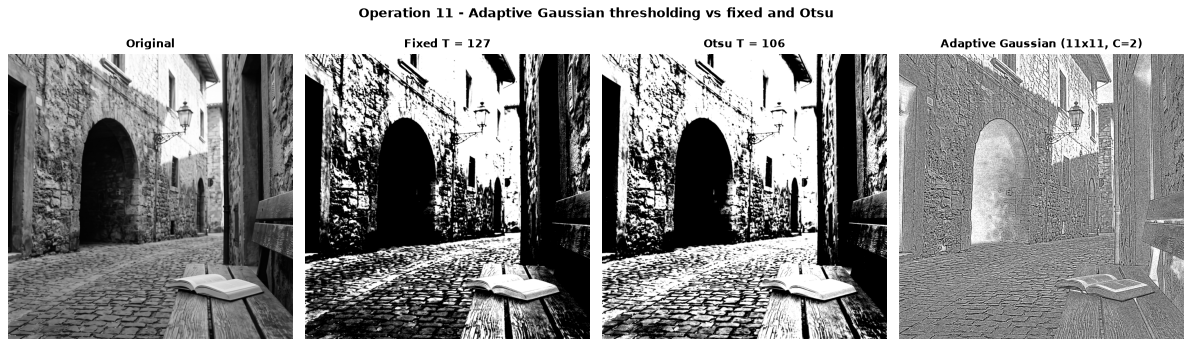

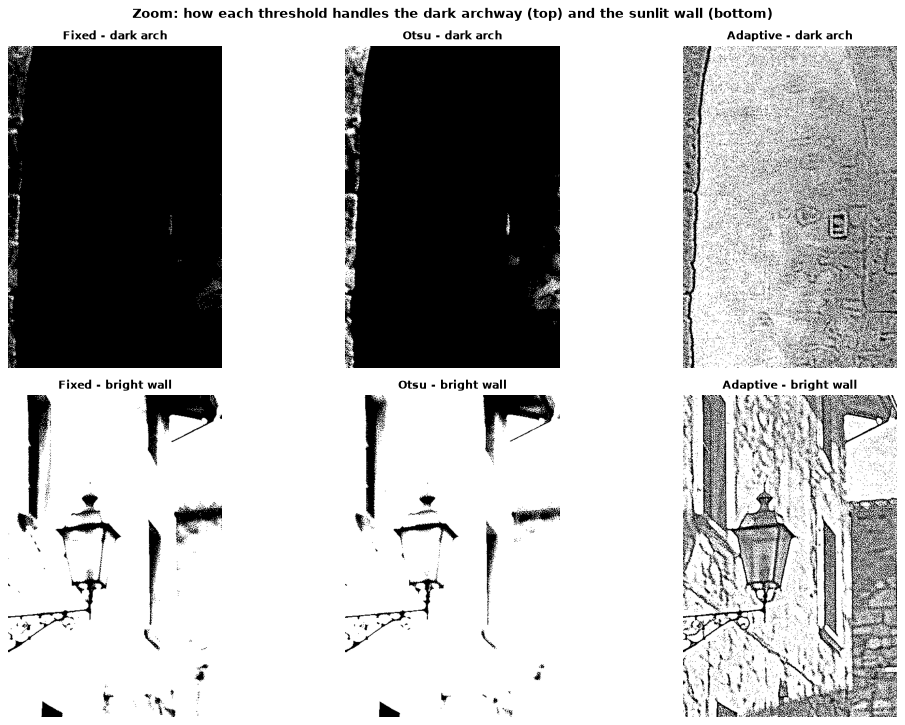

In [25]:
binary_adaptive = cv2.adaptiveThreshold(original, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv2.THRESH_BINARY, 11, 2)

print("Unique output values:", np.unique(binary_adaptive))
for name, m in (("Fixed T=127", binary_fixed), (f"Otsu T={otsu_T:.0f}", binary_otsu), ("Adaptive 11x11, C=2", binary_adaptive)):
    print(f"White pixels - {name:20s}: {100 * np.mean(m == 255):5.2f}%")

def agreement(a, b):
    return 100 * np.mean(a == b)

print(f"\nAgreement adaptive vs fixed: {agreement(binary_adaptive, binary_fixed):.2f}%")
print(f"Agreement adaptive vs Otsu : {agreement(binary_adaptive, binary_otsu):.2f}%")
print(f"Agreement fixed    vs Otsu : {agreement(binary_fixed, binary_otsu):.2f}%")

show_images([original, binary_fixed, binary_otsu, binary_adaptive],
            ["Original", f"Fixed T = {T_fixed}", f"Otsu T = {otsu_T:.0f}", "Adaptive Gaussian (11x11, C=2)"],
            "Operation 11 - Adaptive Gaussian thresholding vs fixed and Otsu", ncols=4)

# zoom on the uneven-lighting regions
show_images([binary_fixed[dark_crop], binary_otsu[dark_crop], binary_adaptive[dark_crop],
             binary_fixed[bright_crop], binary_otsu[bright_crop], binary_adaptive[bright_crop]],
            ["Fixed - dark arch", "Otsu - dark arch", "Adaptive - dark arch",
             "Fixed - bright wall", "Otsu - bright wall", "Adaptive - bright wall"],
            "Zoom: how each threshold handles the dark archway (top) and the sunlit wall (bottom)", ncols=3)

**Observations — adaptive Gaussian thresholding (11 × 11, C = 2)**
- 57.23 % of the pixels are white. Agreement with the fixed mask is only 62.36 % and with Otsu 63.29 %, while fixed and Otsu agree with each other at 87.42 % — adaptive thresholding gives a *very different* kind of result.
- Because each pixel is compared with its own 11 × 11 local mean, the output behaves like a local-contrast / edge map: flat areas, whether light or dark, are mostly white (a pixel only turns black when it is darker than its local mean by more than C = 2), and dark outlines appear where a pixel is darker than its surroundings. In the dark-archway zoom, the fixed and Otsu masks are almost entirely black, while the adaptive mask shows the dark arch edge on the left, the outline of the small fixture (doorbell) and faint stone-block outlines; the smooth dark interior stays mostly white. Because C = 2 is a very small margin, the adaptive mask also picks up a fine speckle of black dots from image grain and compression noise. On the sunlit wall, fixed and Otsu blow out to white while the adaptive mask keeps the lantern, the window frames and the wall texture.
- **When local thresholds help:** unevenly lit scenes such as document pages with shadows, gradients or a flash hotspot, where no single global T separates text from background. **Limitation:** it does not segment large dark and bright *regions* (large flat areas such as the smooth part of the archway turn white, so the dark archway no longer appears as a dark region in the mask) and it is sensitive to noise when C is small, so for this photograph a global method is better for region masks, while adaptive is better for fine detail and edges.

---
## Final summary and integrity check

In [26]:
print_stats([("Original", original),
             ("Brightness +40", bright), ("Brightness -40", darker),
             ("Linear 1.5r", linear),
             ("Centered a=1.5", centered_15), ("Centered a=0.5", centered_05),
             ("Negative", negative),
             ("Gamma 0.5", gamma_05), ("Gamma 2.0", gamma_20),
             ("Global equalization", equalized), ("CLAHE", local),
             ("Fixed T=127", binary_fixed), ("Otsu", binary_otsu), ("Adaptive 11x11", binary_adaptive)],
            "Summary of every result image")

# The original must be unchanged after all operations
reloaded = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
print("Original array identical to a fresh read of the file:", np.array_equal(original, reloaded))
print("Original array still read-only                      :", not original.flags.writeable)
assert np.array_equal(original, reloaded)

Summary of every result image
Image               | Mean   | Std-dev | Min | Max | % pixels = 0 | % pixels = 255
--------------------+--------+---------+-----+-----+--------------+---------------
Original            | 107.27 | 66.41   | 0   | 255 | 0.01         | 0.39          
Brightness +40      | 145.01 | 62.02   | 40  | 255 | 0.00         | 8.04          
Brightness -40      | 71.57  | 60.76   | 0   | 215 | 19.50        | 0.00          
Linear 1.5r         | 149.87 | 81.95   | 0   | 255 | 0.01         | 16.25         
Centered a=1.5      | 100.31 | 82.61   | 0   | 255 | 20.78        | 8.20          
Centered a=0.5      | 117.38 | 33.21   | 64  | 191 | 0.00         | 0.00          
Negative            | 147.73 | 66.41   | 0   | 255 | 0.39         | 0.01          
Gamma 0.5           | 154.40 | 57.83   | 0   | 255 | 0.01         | 0.39          
Gamma 2.0           | 62.00  | 64.87   | 0   | 255 | 9.76         | 0.39          
Global equalization | 128.11 | 73.52   | 0   | 255 | 0.07

### Key concepts (brief explanations)
- **Clipping vs overflow:** *overflow* happens when an 8-bit (`uint8`) calculation exceeds 0–255 and wraps around (240 + 50 → 34). *Clipping* (`np.clip(..., 0, 255)`) saturates the value at 0 or 255 instead. The safe order is: wider type → compute → clip → `astype(np.uint8)` (which truncates fractions).
- **Brightness vs contrast:** brightness adds a constant β to every pixel (shifts the whole histogram); contrast multiplies by α (spreads or compresses the histogram). Centering the contrast at 128 keeps the mid-gray fixed so brightness is not changed at the same time.
- **Gamma convention used here:** s = 255 (r/255)^γ; γ < 1 brightens (lifts shadows), γ > 1 darkens, and 0 and 255 never change.
- **Global vs local enhancement/thresholding:** global methods (equalization, fixed/Otsu thresholds) apply one mapping to the entire image, which is simple and fast and works well when lighting is even. Local methods (CLAHE, adaptive thresholds) compute mappings from neighbourhoods, so they cope better with uneven illumination, at the cost of more noise amplification (CLAHE) or edge-only output (adaptive thresholding).
- **Original preserved:** the original array was read-only throughout and is identical to a fresh read of `input_image.jpg`.